# Heart Disease Prediction Using Optimized Ensemble Learning and Explainable AI
Reproduction of **Mienye & Jere (2024)**, *Information* 15(7), 394 — <https://www.mdpi.com/2078-2489/15/7/394>

**How to use:** run the cells from top to bottom (Runtime → Run all also works; Cell 3 will ask you to allow Google Drive and to upload the two CSV files if it cannot find them).
A first full run with `N_TRIALS = 30` takes roughly 10–25 minutes on a free Colab CPU; set `N_TRIALS = 10` in Cell 2 for a quick trial.

**Educational / research use only — not a medical diagnosis tool.**

**What is reproduced and what is not (read this first)**
* Same models (Random Forest, AdaBoost, XGBoost), same search ranges (paper Tables 3–4), same objective (5-fold CV ROC-AUC), SHAP on the best XGBoost-type model.
* The paper does **not** state its train/test split, preprocessing, random seeds, Bayesian-optimisation library, or how missing Framingham values were handled, so the *exact* numbers cannot be reproduced. Where the paper is silent, this notebook makes a documented choice and does not claim exact reproduction.
* Several rows in the paper's Tables 5–6 are mathematically inconsistent (accuracy outside the range of its own sensitivity/specificity); Cell 10 checks this automatically.
* We never tune on, select on, or re-draw the test set, so your numbers may be noticeably lower than the paper's — especially on Framingham. That is the honest result.

## Revision notes — reliability and explainability updates

This notebook has been updated to improve evaluation and explain individual predictions:
- Adds balanced accuracy, Brier score and log loss alongside accuracy, sensitivity, specificity, F1 and ROC-AUC.
- Uses probability-scale SHAP explanations for Random Forest and XGBoost, so their individual contributions are easier to interpret consistently.
- Shows the individual SHAP table and waterfall plot directly on the Streamlit prediction page.
- Uses the cross-validation-selected threshold as the primary displayed decision threshold, while also showing the conventional 0.50-threshold class.
- Keeps the held-out test set separate from model tuning and model selection.

**Important:** These changes improve transparency and evaluation; they cannot guarantee a specific accuracy or reproduce the paper's reported scores. Re-run the notebook cells in order to regenerate models, metrics, SHAP artifacts, and the app. Outputs are estimates from public datasets and are not medical advice or diagnosis.

**Framingham class-imbalance update (Cells 9A–9G and 11A–11D):** adds a class-weighted XGBoost (`scale_pos_weight` tuned with Optuna on the training data), a cross-validation-based decision threshold, PR-AUC / balanced accuracy / PR curves / confusion matrices, a threshold-only ablation, an optional SMOTE experiment (CV only), SHAP and calibration for the improved model, and an auto-generated before-vs-after summary. All original cells and results are unchanged; the test set is used once for the final evaluation.


### Cell 1 — Install packages
Installs XGBoost, SHAP, Optuna and Streamlit (everything else is pre-installed in Colab).

In [1]:
# CELL 1 — Install the packages we need (takes ~1-2 minutes the first time).
# numpy / pandas / scikit-learn / matplotlib already come with Colab, so we do not reinstall them
# (reinstalling them can force a runtime restart).
!pip install -q "xgboost>=2.0" "shap>=0.45" "optuna>=3.5" "streamlit>=1.35" imbalanced-learn joblib matplotlib
print("Packages installed. If Colab asks you to restart the runtime, restart it and run from Cell 2.")


Packages installed. If Colab asks you to restart the runtime, restart it and run from Cell 2.


### Cell 2 — Imports, reproducibility, settings
Imports libraries, fixes random seeds (42), defines the trial budget and project folders.

In [2]:
# CELL 2 — Imports, reproducibility and global settings
import os, sys, json, random, warnings, time, platform, shutil, re, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, optuna, shap, xgboost, sklearn

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, balanced_accuracy_score, brier_score_loss, log_loss)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
try:
    display            # exists inside notebooks
except NameError:
    display = print

# ---------- reproducibility ----------
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

# ---------- experiment settings (you may change these) ----------
TEST_SIZE = 0.20        # 80 % train / 20 % held-out test, stratified
CV_FOLDS = 5            # five-fold stratified CV, as in the paper
N_TRIALS = int(os.environ.get("HD_TRIALS", 30))          # Bayesian-optimisation trials per model per dataset
TIMEOUT_PER_MODEL = int(os.environ.get("HD_TIMEOUT", 600))  # safety limit (seconds) per model per dataset
# Tip: set N_TRIALS = 10 for a quick first run (~5 min); 30-50 for the final run.

IN_COLAB = "google.colab" in sys.modules

# ---------- project folders ----------
def set_project_dir(path):
    """Create the folder layout and make it the working directory."""
    global PROJECT_DIR, DATA_DIR, ARTIFACT_DIR, RESULTS_DIR, PLOTS_DIR
    PROJECT_DIR = Path(path)
    DATA_DIR, ARTIFACT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "artifacts"
    RESULTS_DIR = PROJECT_DIR / "results"
    PLOTS_DIR = RESULTS_DIR / "plots"
    for d in (DATA_DIR, ARTIFACT_DIR, RESULTS_DIR, PLOTS_DIR, RESULTS_DIR / "shap"):
        d.mkdir(parents=True, exist_ok=True)
    os.chdir(PROJECT_DIR)
    return PROJECT_DIR

set_project_dir(os.environ.get("HD_PROJECT_DIR", "/content/heart_disease_project"))

print("Python      :", platform.python_version())
for lib in (np, pd, sklearn, xgboost, shap, optuna):
    print(f"{lib.__name__:<12}:", lib.__version__)
major_minor = tuple(int(x) for x in sklearn.__version__.split(".")[:2])
if major_minor < (1, 4):
    raise RuntimeError("scikit-learn >= 1.4 is required. Run: !pip install -U scikit-learn  then restart the runtime.")
print("\nProject folder:", PROJECT_DIR)
print(f"Settings: seed={SEED}, test_size={TEST_SIZE}, cv_folds={CV_FOLDS}, n_trials={N_TRIALS}")


Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
sklearn     : 1.6.1
xgboost     : 3.4.1
shap        : 0.54.1
optuna      : 5.0.0

Project folder: /content/heart_disease_project
Settings: seed=42, test_size=0.2, cv_folds=5, n_trials=30


### Cell 3 — Google Drive and datasets
Mounts Drive (so results survive a runtime reset) and finds your two CSV files — or asks you to upload them.

In [3]:
# CELL 3 — Mount Google Drive (recommended) and locate / upload the datasets
USE_GOOGLE_DRIVE = True    # True  = save everything in Google Drive (survives runtime resets)
RELAUNCH_ONLY = False      # True  = you only want to re-open the app later (skip dataset checks)

CLEVELAND_FILE = "Heart_disease_cleveland_new.csv"
FRAMINGHAM_FILE = "framingham_heart_study.csv"

if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    set_project_dir("/content/drive/MyDrive/heart_disease_project")
print("Project folder:", PROJECT_DIR)

if not RELAUNCH_ONLY:
    SEARCH_DIRS = [DATA_DIR, Path.cwd(), Path("/content"), Path("/content/drive/MyDrive"),
                   Path("/content/drive/MyDrive/Colab Notebooks"), Path("/mnt/user-data/uploads")]

    def locate(filename):
        for d in SEARCH_DIRS:
            p = d / filename
            if p.exists():
                return p
        return None

    wanted = [CLEVELAND_FILE, FRAMINGHAM_FILE]
    missing = [f for f in wanted if locate(f) is None]
    if missing and IN_COLAB:
        from google.colab import files
        print("Please upload these missing file(s):", missing)
        uploaded = files.upload()
        for name, data in uploaded.items():
            # Colab renames duplicates like 'file (1).csv' - map them back to the expected name
            target = next((w for w in wanted if name.lower().startswith(Path(w).stem.lower())), name)
            (DATA_DIR / target).write_bytes(data)
        missing = [f for f in wanted if locate(f) is None]
    if missing:
        raise FileNotFoundError(
            f"Dataset file(s) not found: {missing}\n"
            f"Upload them to the Colab file browser, or copy them into: {DATA_DIR}\n"
            "File names must match exactly (including capital letters).")

    for f in wanted:
        src, dst = locate(f), DATA_DIR / f
        if src.resolve() != dst.resolve():
            shutil.copy(src, dst)
        print("Found:", dst)

    print("\nOptional files (the notebook does its own split, so they are NOT needed):")
    for f in ["cleveland_train_preprocessed.csv", "cleveland_test_preprocessed.csv",
              "framingham_train_preprocessed.csv", "framingham_test_preprocessed.csv"]:
        print(f"  {f}: {'found (ignored)' if locate(f) else 'not found (fine)'}")


Mounted at /content/drive
Project folder: /content/drive/MyDrive/heart_disease_project
Found: /content/drive/MyDrive/heart_disease_project/data/Heart_disease_cleveland_new.csv
Found: /content/drive/MyDrive/heart_disease_project/data/framingham_heart_study.csv

Optional files (the notebook does its own split, so they are NOT needed):
  cleveland_train_preprocessed.csv: not found (fine)
  cleveland_test_preprocessed.csv: not found (fine)
  framingham_train_preprocessed.csv: not found (fine)
  framingham_test_preprocessed.csv: not found (fine)


### Cell 4 — Inspect datasets
Checks columns, data types, missing values, duplicates and class balance. Stops with a clear message if a column is missing.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CLEVELAND  |  file: Heart_disease_cleveland_new.csv  |  shape: (303, 14)  |  target column: 'target'
Input features (13): ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target 'target' is excluded from the input features: True


,dtype,missing,missing_%,unique_values
age,int64,0,0.0,41
sex,int64,0,0.0,2
cp,int64,0,0.0,4
trestbps,int64,0,0.0,50
chol,int64,0,0.0,152
fbs,int64,0,0.0,2
restecg,int64,0,0.0,3
thalach,int64,0,0.0,91
exang,int64,0,0.0,2
oldpeak,float64,0,0.0,40


Duplicate rows: 0
Target distribution: {0: '164 (54.1%)', 1: '139 (45.9%)'}
Majority-class accuracy (a model that always predicts 0): 0.541
Imbalance ratio (majority:minority) = 1.18 : 1


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,2.16,0.96,0.0,2.0,2.0,3.0,3.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


FRAMINGHAM  |  file: framingham_heart_study.csv  |  shape: (4240, 16)  |  target column: 'TenYearCHD'
Input features (15): ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Target 'TenYearCHD' is excluded from the input features: True


,dtype,missing,missing_%,unique_values
male,int64,0,0.00,2
age,int64,0,0.00,39
education,float64,105,2.48,4
currentSmoker,int64,0,0.00,2
cigsPerDay,float64,29,0.68,33
BPMeds,float64,53,1.25,2
prevalentStroke,int64,0,0.00,2
prevalentHyp,int64,0,0.00,2
diabetes,int64,0,0.00,2
totChol,float64,50,1.18,248


Duplicate rows: 0
Target distribution: {0: '3596 (84.8%)', 1: '644 (15.2%)'}
Majority-class accuracy (a model that always predicts 0): 0.848
Imbalance ratio (majority:minority) = 5.58 : 1


,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.43,0.50,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.58,8.57,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.98,1.02,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.49,0.50,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.01,11.92,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.03,0.17,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.01,0.08,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.31,0.46,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.03,0.16,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.70,44.59,107.00,206.00,234.0,263.00,696.0


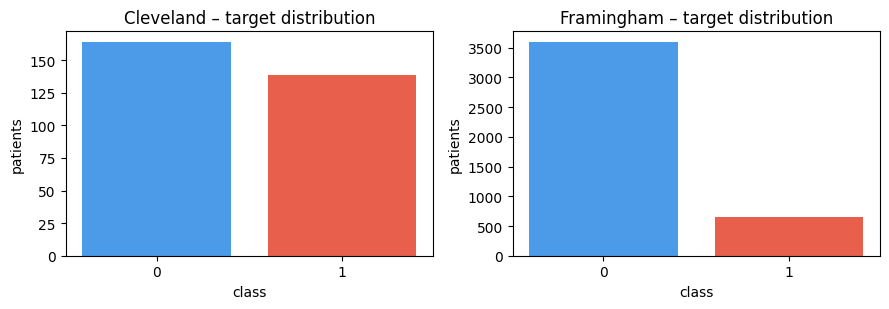

In [5]:
# CELL 4 — Inspect both datasets: columns, types, missing values, duplicates, target balance
CLEVELAND_FEATURES = {            # name: (group, description)
    "age": ("numeric", "Age in years"),
    "sex": ("categorical", "Sex (1 = male; 0 = female)"),
    "cp": ("categorical", "Chest pain type (0-3)"),
    "trestbps": ("numeric", "Resting blood pressure (mm Hg)"),
    "chol": ("numeric", "Serum cholesterol (mg/dL)"),
    "fbs": ("categorical", "Fasting blood sugar > 120 mg/dL (1 = true)"),
    "restecg": ("categorical", "Resting electrocardiographic result (0-2)"),
    "thalach": ("numeric", "Maximum heart rate achieved"),
    "exang": ("categorical", "Exercise-induced angina (1 = yes)"),
    "oldpeak": ("numeric", "ST depression induced by exercise relative to rest"),
    "slope": ("categorical", "Slope of the peak exercise ST segment (0-2)"),
    "ca": ("numeric", "Number of major vessels (0-3) coloured by fluoroscopy"),
    "thal": ("categorical", "Thalassemia (1-3)"),
}
FRAMINGHAM_FEATURES = {
    "male": ("categorical", "Sex (1 = male; 0 = female)"),
    "age": ("numeric", "Age in years"),
    "education": ("categorical", "Education level (1-4)"),
    "currentSmoker": ("categorical", "Current smoker (1 = yes)"),
    "cigsPerDay": ("numeric", "Average cigarettes smoked per day"),
    "BPMeds": ("categorical", "On blood-pressure medication (1 = yes)"),
    "prevalentStroke": ("categorical", "Previous stroke (1 = yes)"),
    "prevalentHyp": ("categorical", "Hypertensive (1 = yes)"),
    "diabetes": ("categorical", "Diabetes (1 = yes)"),
    "totChol": ("numeric", "Total cholesterol (mg/dL)"),
    "sysBP": ("numeric", "Systolic blood pressure (mm Hg)"),
    "diaBP": ("numeric", "Diastolic blood pressure (mm Hg)"),
    "BMI": ("numeric", "Body mass index"),
    "heartRate": ("numeric", "Heart rate (beats per minute)"),
    "glucose": ("numeric", "Glucose level (mg/dL)"),
}
DATASETS = {
    "cleveland": dict(label="Cleveland", file=CLEVELAND_FILE, target="target", features=CLEVELAND_FEATURES,
                      target_meaning={0: "No heart disease", 1: "Heart disease"}),
    "framingham": dict(label="Framingham", file=FRAMINGHAM_FILE, target="TenYearCHD", features=FRAMINGHAM_FEATURES,
                       target_meaning={0: "No CHD within 10 years", 1: "CHD within 10 years"}),
}
for cfg in DATASETS.values():
    cfg["feature_names"] = list(cfg["features"])
    cfg["numeric"] = [f for f, (g, _) in cfg["features"].items() if g == "numeric"]
    cfg["categorical"] = [f for f, (g, _) in cfg["features"].items() if g == "categorical"]


def load_and_validate(key):
    """Read a CSV, tidy column names, verify that every expected column exists."""
    cfg = DATASETS[key]
    path = DATA_DIR / cfg["file"]
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Re-run Cell 3 to locate/upload it.")
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]                 # remove stray spaces
    expected = cfg["feature_names"] + [cfg["target"]]
    lower = {c.lower(): c for c in df.columns}
    df = df.rename(columns={lower[e.lower()]: e for e in expected if e.lower() in lower})   # fix capitalisation only
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"[{cfg['label']}] missing expected column(s): {missing}\n"
                         f"Columns found in the file: {list(df.columns)}")
    extra = [c for c in df.columns if c not in expected]
    if extra:
        print(f"[{cfg['label']}] note: ignoring extra column(s): {extra}")
    df = df[expected].copy()
    tgt = cfg["target"]
    if df[tgt].nunique() > 2:        # some Cleveland versions use 0-4; 'any disease' = 1
        print(f"[{cfg['label']}] target has {df[tgt].nunique()} levels -> converting to binary (0 vs >0).")
        df[tgt] = (df[tgt] > 0).astype(int)
    return df

RAW = {k: load_and_validate(k) for k in DATASETS}

for key, df in RAW.items():
    cfg = DATASETS[key]; tgt = cfg["target"]
    print("=" * 78)
    print(f"{cfg['label'].upper()}  |  file: {cfg['file']}  |  shape: {df.shape}  |  target column: '{tgt}'")
    print("=" * 78)
    print(f"Input features ({len(cfg['feature_names'])}): {cfg['feature_names']}")
    print(f"Target '{tgt}' is excluded from the input features:", tgt not in cfg["feature_names"])
    info = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2), "unique_values": df.nunique()})
    display(info)
    print(f"Duplicate rows: {df.duplicated().sum()}")
    counts = df[tgt].value_counts().sort_index()
    pct = (counts / counts.sum() * 100).round(1)
    print("Target distribution:", {int(k): f"{v} ({pct[k]}%)" for k, v in counts.items()})
    print(f"Majority-class accuracy (a model that always predicts 0): {counts.max() / counts.sum():.3f}")
    print(f"Imbalance ratio (majority:minority) = {counts.max() / counts.min():.2f} : 1")
    display(df.describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (key, df) in zip(axes, RAW.items()):
    vc = df[DATASETS[key]["target"]].value_counts().sort_index()
    ax.bar([str(i) for i in vc.index], vc.values, color=["#4C9BE8", "#E8604C"])
    ax.set_title(f"{DATASETS[key]['label']} – target distribution"); ax.set_xlabel("class"); ax.set_ylabel("patients")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "target_distributions.png", dpi=150); plt.show()


### Cell 5 — Clean data and stratified split
Removes duplicates, forces numeric types and creates ONE fixed 80/20 stratified split. The test set is locked away until Cell 9.

In [6]:
# CELL 5 — Clean the data and create stratified train / test splits (test set is locked away until Cell 9)
def clean_dataframe(df, cfg):
    """Force numeric types, drop rows with a missing target and exact duplicates.
    Missing FEATURE values are kept here and imputed later inside the pipeline (fit on training data only)."""
    df = df.copy()
    n_start = len(df)
    for c in cfg["feature_names"] + [cfg["target"]]:
        before = df[c].isna().sum()
        df[c] = pd.to_numeric(df[c], errors="coerce")
        if df[c].isna().sum() > before:
            print(f"  warning: {c}: {df[c].isna().sum() - before} non-numeric value(s) became missing")
    df = df.dropna(subset=[cfg["target"]])
    n_dups = int(df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)
    return df, dict(rows_raw=n_start, duplicates_removed=n_dups, rows_clean=len(df))

SPLITS, CLEAN_INFO = {}, {}
for key, cfg in DATASETS.items():
    df, info = clean_dataframe(RAW[key], cfg)
    X, y = df[cfg["feature_names"]], df[cfg["target"]].astype(int)
    assert cfg["target"] not in X.columns, "target leaked into features!"
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)       # ONE fixed split – never re-drawn
    assert not set(X_train.index) & set(X_test.index), "train/test overlap!"
    SPLITS[key] = dict(X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)
    CLEAN_INFO[key] = {**info, "n_features": X.shape[1], "train_size": len(X_train), "test_size": len(X_test),
                       "train_positive": int(y_train.sum()), "test_positive": int(y_test.sum())}
    print(f"{cfg['label']:<11} rows={len(df):>5} | train={len(X_train):>5} (positives {y_train.mean():.1%}) "
          f"| test={len(X_test):>4} (positives {y_test.mean():.1%}) | duplicates removed: {info['duplicates_removed']}")

print("\nThe test sets are now set aside. They are NOT used for tuning, threshold selection or model selection.")


Cleveland   rows=  303 | train=  242 (positives 45.9%) | test=  61 (positives 45.9%) | duplicates removed: 0
Framingham  rows= 4240 | train= 3392 (positives 15.2%) | test= 848 (positives 15.2%) | duplicates removed: 0

The test sets are now set aside. They are NOT used for tuning, threshold selection or model selection.


### Cell 6 — Leakage-free preprocessing
Builds the imputation pipeline and fits it on the training data only.

In [7]:
# CELL 6 — Preprocessing pipelines (fitted on TRAINING data only -> no leakage)
# Design choices:
#   * numeric columns  -> median imputation;  categorical/binary codes -> most-frequent imputation
#   * NO scaling and NO one-hot encoding: tree ensembles do not need them, and keeping the original
#     columns means SHAP plots and the app use real clinical units (and the paper's 13 / 15 features).
#   * The imputer lives inside a scikit-learn Pipeline, so during cross-validation it is re-fitted
#     on each training fold only.
def build_preprocessor(key):
    cfg = DATASETS[key]
    pre = ColumnTransformer(
        [("num", SimpleImputer(strategy="median"), cfg["numeric"]),
         ("cat", SimpleImputer(strategy="most_frequent"), cfg["categorical"])],
        verbose_feature_names_out=False)
    pre.set_output(transform="pandas")
    return pre

for key, cfg in DATASETS.items():
    sp = SPLITS[key]
    pre = build_preprocessor(key).fit(sp["X_train"])                 # <- fitted on train only
    Xt = pre.transform(sp["X_train"]); Xe = pre.transform(sp["X_test"])
    print(f"{cfg['label']}: train -> {Xt.shape}, test -> {Xe.shape}, remaining NaNs: {int(Xt.isna().sum().sum() + Xe.isna().sum().sum())}")
    print("   output columns:", list(Xt.columns))
    miss_cols = [c for c in cfg["feature_names"] if sp["X_train"][c].isna().any()]
    if miss_cols:
        med = pre.named_transformers_["num"].statistics_; names = cfg["numeric"]
        print("   columns with missing values in TRAIN:", miss_cols)
        print("   imputation values learnt from train (numeric):", {n: round(float(v), 2) for n, v in zip(names, med) if n in miss_cols})
        # Leakage demonstration: statistics fitted on train+test would differ slightly
        alt = SimpleImputer(strategy="median").fit(pd.concat([sp["X_train"], sp["X_test"]])[cfg["numeric"]]).statistics_
        print("   (for comparison, train+test medians would be:", {n: round(float(v), 2) for n, v in zip(names, alt) if n in miss_cols}, "- we do NOT use these)")
print("\nPreprocessing OK.")


Cleveland: train -> (242, 13), test -> (61, 13), remaining NaNs: 0
   output columns: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
Framingham: train -> (3392, 15), test -> (848, 15), remaining NaNs: 0
   output columns: ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']
   columns with missing values in TRAIN: ['education', 'cigsPerDay', 'BPMeds', 'totChol', 'BMI', 'heartRate', 'glucose']
   imputation values learnt from train (numeric): {'cigsPerDay': 0.0, 'totChol': 234.0, 'BMI': 25.38, 'heartRate': 75.0, 'glucose': 78.0}
   (for comparison, train+test medians would be: {'cigsPerDay': 0.0, 'totChol': 234.0, 'BMI': 25.4, 'heartRate': 75.0, 'glucose': 78.0} - we do NOT use these)

Preprocessing OK.


### Cell 7 — Baseline models
Trains default Random Forest, AdaBoost and XGBoost; defines the metric functions (accuracy, precision, sensitivity, specificity, F1, ROC-AUC, confusion matrix).

In [8]:
# CELL 7 — Baseline models (default hyper-parameters) + evaluation helpers
MODEL_NAMES = ["Random Forest", "AdaBoost", "XGBoost"]
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

def make_estimator(name, params=None):
    p = dict(params or {})
    if name == "Random Forest":
        return RandomForestClassifier(random_state=SEED, n_jobs=1, **p)
    if name == "AdaBoost":
        depth = p.pop("base_depth", 1)                       # 1 = scikit-learn's default decision stump
        return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth, random_state=SEED),
                                  random_state=SEED, **p)
    if name == "XGBoost":
        return XGBClassifier(random_state=SEED, eval_metric="logloss", tree_method="hist", n_jobs=1, **p)
    raise ValueError(name)

def make_pipeline(key, name, params=None):
    return Pipeline([("preprocess", build_preprocessor(key)), ("model", make_estimator(name, params))])

def compute_metrics(y_true, proba, threshold=0.5):
    y_true = np.asarray(y_true); pred = (np.asarray(proba) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    proba = np.clip(np.asarray(proba, dtype=float), 1e-7, 1 - 1e-7)
    return dict(accuracy=accuracy_score(y_true, pred),
                balanced_accuracy=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                sensitivity=recall_score(y_true, pred, zero_division=0),
                specificity=tn / (tn + fp) if (tn + fp) else np.nan,
                f1=f1_score(y_true, pred, zero_division=0),
                roc_auc=roc_auc_score(y_true, proba),
                brier_score=brier_score_loss(y_true, proba),
                log_loss=log_loss(y_true, proba, labels=[0, 1]),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

RESULTS, CV_ROWS, MODELS, PREDS = [], [], {}, {}

def record(key, stage, name, pipe, threshold=0.5, store=True):
    """Evaluate a FITTED pipeline on train and held-out test; remember results, model and test probabilities."""
    sp = SPLITS[key]
    for split, X, y in (("train", sp["X_train"], sp["y_train"]), ("test", sp["X_test"], sp["y_test"])):
        proba = pipe.predict_proba(X)[:, 1]
        RESULTS.append(dict(dataset=key, stage=stage, model=name, split=split, threshold=threshold,
                            **compute_metrics(y, proba, threshold)))
        if split == "test" and store:
            PREDS[(key, stage, name)] = proba
    if store:
        MODELS[(key, stage, name)] = pipe

def record_cv(key, stage, name, params=None):
    """Five-fold stratified CV ROC-AUC on the TRAINING set only."""
    sp = SPLITS[key]
    scores = cross_val_score(make_pipeline(key, name, params), sp["X_train"], sp["y_train"],
                             cv=skf, scoring="roc_auc", n_jobs=-1)
    CV_ROWS.append(dict(dataset=key, stage=stage, model=name, cv_roc_auc_mean=scores.mean(), cv_roc_auc_std=scores.std()))
    return scores

SHOW_COLS = ["dataset", "model", "accuracy", "balanced_accuracy", "precision", "sensitivity",
             "specificity", "f1", "roc_auc", "brier_score", "log_loss"]
def show_table(stage, split="test"):
    df = pd.DataFrame(RESULTS)
    sub = df[(df.stage == stage) & (df.split == split)]
    display(sub[SHOW_COLS].round(3).reset_index(drop=True))

# ---- train baselines ----
for key in DATASETS:
    sp = SPLITS[key]
    for name in MODEL_NAMES:
        pipe = make_pipeline(key, name).fit(sp["X_train"], sp["y_train"])
        record_cv(key, "baseline", name)
        record(key, "baseline", name, pipe)
    print(f"{DATASETS[key]['label']}: baselines trained.")

print("\nBASELINE models – HELD-OUT TEST results (threshold 0.5):")
show_table("baseline", "test")
print("5-fold CV ROC-AUC on the training set (mean ± std):")
display(pd.DataFrame(CV_ROWS).query("stage=='baseline'").round(3).reset_index(drop=True))


Cleveland: baselines trained.
Framingham: baselines trained.

BASELINE models – HELD-OUT TEST results (threshold 0.5):


,dataset,model,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,roc_auc,brier_score,log_loss
0,cleveland,Random Forest,0.918,0.922,0.871,0.964,0.879,0.915,0.960,0.086,0.309
1,cleveland,AdaBoost,0.885,0.891,0.818,0.964,0.818,0.885,0.968,0.166,0.521
2,cleveland,XGBoost,0.852,0.858,0.788,0.929,0.788,0.852,0.919,0.123,0.469
3,framingham,Random Forest,0.844,0.523,0.421,0.062,0.985,0.108,0.636,0.129,0.442
4,framingham,AdaBoost,0.850,0.517,0.625,0.039,0.996,0.073,0.682,0.153,0.487
5,framingham,XGBoost,0.818,0.530,0.273,0.116,0.944,0.163,0.589,0.148,0.556


5-fold CV ROC-AUC on the training set (mean ± std):


,dataset,stage,model,cv_roc_auc_mean,cv_roc_auc_std
0,cleveland,baseline,Random Forest,0.879,0.033
1,cleveland,baseline,AdaBoost,0.872,0.034
2,cleveland,baseline,XGBoost,0.866,0.023
3,framingham,baseline,Random Forest,0.707,0.038
4,framingham,baseline,AdaBoost,0.706,0.035
5,framingham,baseline,XGBoost,0.672,0.015


### Cell 8 — Bayesian hyper-parameter optimisation
Optuna TPE with 5-fold stratified CV on the training data (objective: ROC-AUC). The test set is not used.

Running Bayesian optimisation: 30 trials per model (max 600s each)...
  Cleveland  Random Forest  best CV AUC = 0.9041 ± 0.0189 (30 trials, 30s)
  Cleveland  AdaBoost       best CV AUC = 0.8968 ± 0.0246 (30 trials, 32s)
  Cleveland  XGBoost        best CV AUC = 0.9054 ± 0.0277 (30 trials, 11s)
  Framingham Random Forest  best CV AUC = 0.7230 ± 0.0345 (30 trials, 71s)
  Framingham AdaBoost       best CV AUC = 0.7199 ± 0.0346 (30 trials, 175s)
  Framingham XGBoost        best CV AUC = 0.7286 ± 0.0321 (30 trials, 18s)


,dataset,model,cv_roc_auc_mean,cv_roc_auc_std,n_trials
0,cleveland,Random Forest,0.9041,0.0189,30
1,cleveland,AdaBoost,0.8968,0.0246,30
2,cleveland,XGBoost,0.9054,0.0277,30
3,framingham,Random Forest,0.7230,0.0345,30
4,framingham,AdaBoost,0.7199,0.0346,30
5,framingham,XGBoost,0.7286,0.0321,30


cleveland  Random Forest  {"n_estimators": 119, "max_depth": 5, "min_samples_split": 5, "min_samples_leaf": 8, "max_features": "log2"}
cleveland  AdaBoost       {"n_estimators": 154, "learning_rate": 0.020513382630874502, "base_depth": 1}
cleveland  XGBoost        {"n_estimators": 424, "max_depth": 7, "learning_rate": 0.0101965995882772, "subsample": 0.8819378248212743, "colsample_bytree": 0.6184298959155285, "min_child_weight": 9, "reg_lambda": 3.2203839774813434, "gamma": 1.4920191149452573}
framingham Random Forest  {"n_estimators": 116, "max_depth": 5, "min_samples_split": 20, "min_samples_leaf": 10, "max_features": 0.5}
framingham AdaBoost       {"n_estimators": 341, "learning_rate": 0.1783918988777906, "base_depth": 1}
framingham XGBoost        {"n_estimators": 333, "max_depth": 3, "learning_rate": 0.016299268964978127, "subsample": 0.20694337595082984, "colsample_bytree": 0.3572876813132011, "min_child_weight": 2, "reg_lambda": 0.4577793268446145, "gamma": 4.784170593778772}


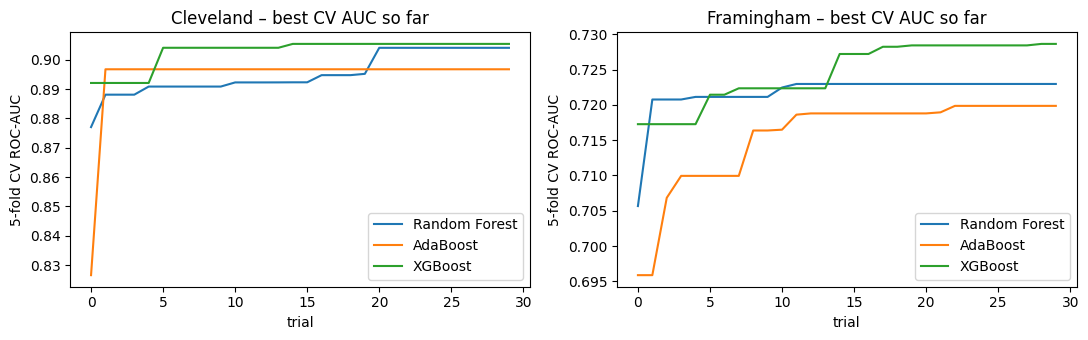

In [9]:
# CELL 8 — Bayesian hyper-parameter optimisation (Optuna TPE, 5-fold stratified CV, objective = mean ROC-AUC)
# This cell uses ONLY the training data. The test set is not touched here.
#
# Search ranges: the first parameters of each model are the ranges from the paper's Tables 3 and 4.
# Parameters marked (+) are EXTRA ones you asked for that the paper does not list.
# The paper does not say which Bayesian-optimisation library it used, so Optuna's TPE sampler
# (a sequential model-based / Bayesian method) is used here instead of an unknown implementation.
def suggest_params(trial, name):
    if name == "Random Forest":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 10, 200),
            max_depth=trial.suggest_categorical("max_depth", [None, 5, 10, 20, 30]),
            min_samples_split=trial.suggest_categorical("min_samples_split", [2, 5, 10, 20]),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),                      # (+)
            max_features=trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 1.0]))  # (+)
    if name == "AdaBoost":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 10, 1000, log=True),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 1.0, log=True),
            base_depth=trial.suggest_int("base_depth", 1, 3))                                   # (+) weak-learner depth
    if name == "XGBoost":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 100, 1000),
            max_depth=trial.suggest_int("max_depth", 3, 10),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            subsample=trial.suggest_float("subsample", 0.2, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),                 # (+)
            min_child_weight=trial.suggest_int("min_child_weight", 1, 10),                      # (+)
            reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),                 # (+)
            gamma=trial.suggest_float("gamma", 0.0, 5.0))                                       # (+)
    raise ValueError(name)

TUNED = {}   # (dataset, model) -> dict(params, cv_mean, cv_std, n_trials, history)

def tune(key, name):
    sp = SPLITS[key]
    def objective(trial):
        params = suggest_params(trial, name)
        scores = cross_val_score(make_pipeline(key, name, params), sp["X_train"], sp["y_train"],
                                 cv=skf, scoring="roc_auc", n_jobs=-1, error_score="raise")
        trial.set_user_attr("cv_std", float(scores.std()))
        return float(scores.mean())
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=min(10, N_TRIALS)))
    t0 = time.time()
    study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_PER_MODEL, show_progress_bar=False)
    best = study.best_trial
    TUNED[(key, name)] = dict(params=best.params, cv_mean=best.value, cv_std=best.user_attrs["cv_std"],
                              n_trials=len(study.trials), seconds=time.time() - t0,
                              history=[t.value for t in study.trials if t.value is not None])
    study.trials_dataframe().to_csv(RESULTS_DIR / f"optuna_trials_{key}_{name.replace(' ', '_')}.csv", index=False)
    print(f"  {DATASETS[key]['label']:<10} {name:<14} best CV AUC = {best.value:.4f} ± {best.user_attrs['cv_std']:.4f} "
          f"({len(study.trials)} trials, {time.time() - t0:.0f}s)")

print(f"Running Bayesian optimisation: {N_TRIALS} trials per model (max {TIMEOUT_PER_MODEL}s each)...")
for key in DATASETS:
    for name in MODEL_NAMES:
        tune(key, name)

# ---- summary tables + convergence plot ----
rows = [dict(dataset=k, model=n, cv_roc_auc_mean=v["cv_mean"], cv_roc_auc_std=v["cv_std"], n_trials=v["n_trials"],
             best_params=json.dumps(v["params"])) for (k, n), v in TUNED.items()]
BEST_PARAMS_DF = pd.DataFrame(rows)
display(BEST_PARAMS_DF.drop(columns="best_params").round(4))
for r in rows:
    print(f"{r['dataset']:<10} {r['model']:<14} {r['best_params']}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key in zip(axes, DATASETS):
    for name in MODEL_NAMES:
        h = TUNED[(key, name)]["history"]; ax.plot(np.maximum.accumulate(h), label=name)
    ax.set_title(f"{DATASETS[key]['label']} – best CV AUC so far"); ax.set_xlabel("trial"); ax.set_ylabel("5-fold CV ROC-AUC"); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "optimization_history.png", dpi=150); plt.show()


### Cell 9 — Evaluate optimised models on the untouched test sets
Refits each tuned model, evaluates once on the test set, picks the best model from CV evidence only, and draws confusion matrices and ROC curves.

Cleveland: best optimised model by CV AUC -> XGBoost  {'Random Forest': 0.9041, 'AdaBoost': 0.8968, 'XGBoost': 0.9054}
Framingham: best optimised model by CV AUC -> XGBoost  {'Random Forest': 0.723, 'AdaBoost': 0.7199, 'XGBoost': 0.7286}
Cleveland: CV-selected threshold for XGBoost = 0.52
Framingham: CV-selected threshold for XGBoost = 0.15

OPTIMISED models – HELD-OUT TEST results (threshold 0.5):


,dataset,model,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,roc_auc,brier_score,log_loss
0,cleveland,Random Forest,0.902,0.904,0.867,0.929,0.879,0.897,0.961,0.104,0.357
1,cleveland,AdaBoost,0.869,0.868,0.857,0.857,0.879,0.857,0.945,0.111,0.378
2,cleveland,XGBoost,0.852,0.856,0.806,0.893,0.818,0.847,0.949,0.100,0.339
3,framingham,Random Forest,0.847,0.502,0.333,0.008,0.997,0.015,0.678,0.122,0.401
4,framingham,AdaBoost,0.848,0.506,0.500,0.016,0.997,0.030,0.684,0.146,0.472
5,framingham,XGBoost,0.849,0.513,0.571,0.031,0.996,0.059,0.689,0.121,0.398


OPTIMISED best model with the CV-selected threshold (extra row, still honest – threshold from training CV):


,dataset,model,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,roc_auc,brier_score,log_loss
0,cleveland,XGBoost,0.869,0.871,0.833,0.893,0.848,0.862,0.949,0.100,0.339
1,framingham,XGBoost,0.644,0.631,0.239,0.612,0.650,0.343,0.689,0.121,0.398



Baseline -> Optimised change on the test set:


,dataset,model,accuracy_base,accuracy_opt,Δaccuracy,sensitivity_base,sensitivity_opt,Δsensitivity,roc_auc_base,roc_auc_opt,Δroc_auc
0,cleveland,Random Forest,0.918,0.902,-0.016,0.964,0.929,-0.036,0.960,0.961,0.001
1,cleveland,AdaBoost,0.885,0.869,-0.016,0.964,0.857,-0.107,0.968,0.945,-0.023
2,cleveland,XGBoost,0.852,0.852,0.000,0.929,0.893,-0.036,0.919,0.949,0.030
3,framingham,Random Forest,0.844,0.847,0.002,0.062,0.008,-0.054,0.636,0.678,0.041
4,framingham,AdaBoost,0.850,0.848,-0.002,0.039,0.016,-0.023,0.682,0.684,0.002
5,framingham,XGBoost,0.818,0.849,0.031,0.116,0.031,-0.085,0.589,0.689,0.100


Cleveland: a model that predicts EVERYONE as negative would score accuracy 0.541 with sensitivity 0.000.
Framingham: a model that predicts EVERYONE as negative would score accuracy 0.848 with sensitivity 0.000.


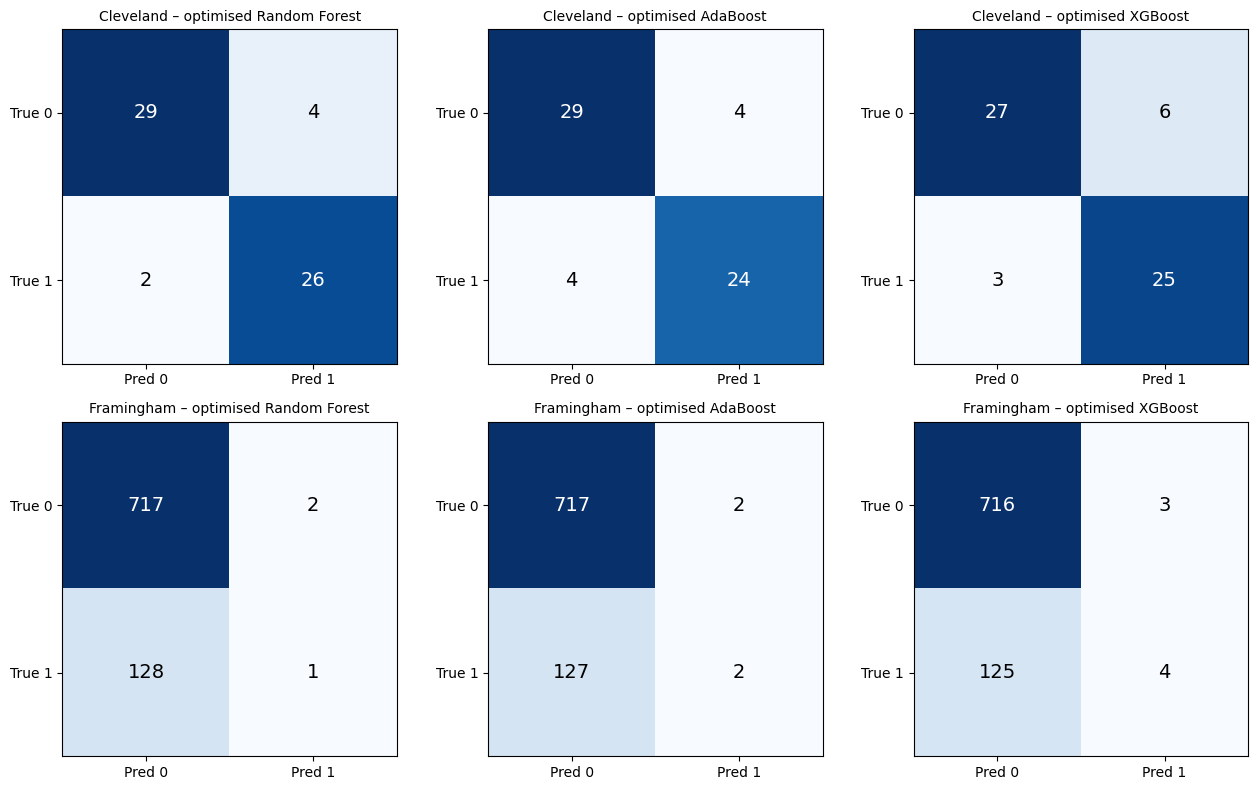

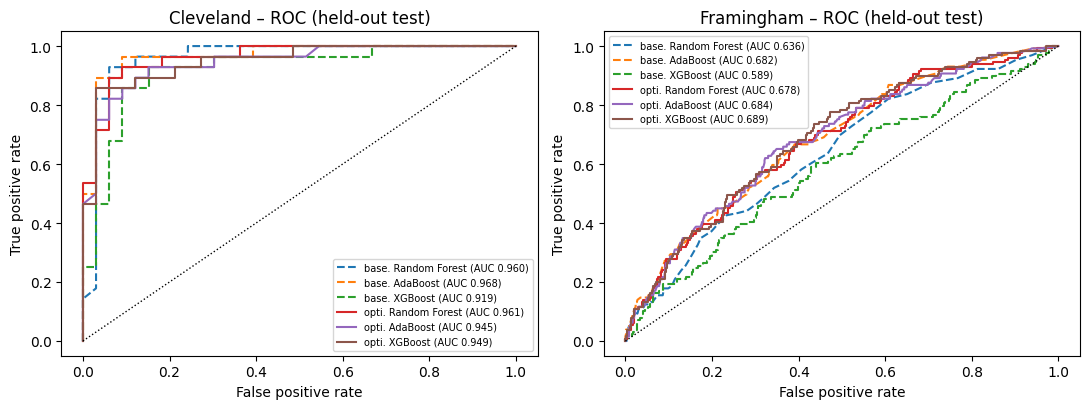

In [10]:
# CELL 9 — Re-fit the optimised models on the training set and evaluate ONCE on the untouched test set
for key in DATASETS:
    sp = SPLITS[key]
    for name in MODEL_NAMES:
        params = TUNED[(key, name)]["params"]
        pipe = make_pipeline(key, name, params).fit(sp["X_train"], sp["y_train"])
        record(key, "optimized", name, pipe)
        CV_ROWS.append(dict(dataset=key, stage="optimized", model=name,
                            cv_roc_auc_mean=TUNED[(key, name)]["cv_mean"], cv_roc_auc_std=TUNED[(key, name)]["cv_std"]))

# ---- choose the best model using TRAINING-ONLY evidence (highest 5-fold CV AUC) ----
# (The paper's Algorithm 1 picks the model with the best TEST AUC; we deliberately do not, to avoid selecting on test data.)
BEST, THRESH_CV = {}, {}
for key in DATASETS:
    cand = {n: TUNED[(key, n)]["cv_mean"] for n in MODEL_NAMES}
    BEST[key] = max(cand, key=cand.get)
    print(f"{DATASETS[key]['label']}: best optimised model by CV AUC -> {BEST[key]}  {({k: round(v, 4) for k, v in cand.items()})}")

# ---- decision threshold chosen from OUT-OF-FOLD training predictions (Youden's J), never from the test set ----
for key in DATASETS:
    sp = SPLITS[key]; name = BEST[key]
    oof = cross_val_predict(make_pipeline(key, name, TUNED[(key, name)]["params"]), sp["X_train"], sp["y_train"],
                            cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    grid = np.linspace(0.05, 0.95, 91)
    youden = [compute_metrics(sp["y_train"], oof, t)["sensitivity"] + compute_metrics(sp["y_train"], oof, t)["specificity"] - 1 for t in grid]
    THRESH_CV[key] = float(grid[int(np.argmax(youden))])
    record(key, "optimized-cv-threshold", name, MODELS[(key, "optimized", name)], threshold=THRESH_CV[key], store=False)
    print(f"{DATASETS[key]['label']}: CV-selected threshold for {name} = {THRESH_CV[key]:.2f}")

print("\nOPTIMISED models – HELD-OUT TEST results (threshold 0.5):")
show_table("optimized", "test")
print("OPTIMISED best model with the CV-selected threshold (extra row, still honest – threshold from training CV):")
show_table("optimized-cv-threshold", "test")

# ---- baseline vs optimised ----
df = pd.DataFrame(RESULTS); t = df[df.split == "test"]
cmp = t[t.stage == "baseline"].merge(t[t.stage == "optimized"], on=["dataset", "model"], suffixes=("_base", "_opt"))
for m in ["accuracy", "sensitivity", "specificity", "f1", "roc_auc"]:
    cmp[f"Δ{m}"] = cmp[f"{m}_opt"] - cmp[f"{m}_base"]
print("\nBaseline -> Optimised change on the test set:")
display(cmp[["dataset", "model", "accuracy_base", "accuracy_opt", "Δaccuracy", "sensitivity_base", "sensitivity_opt", "Δsensitivity",
             "roc_auc_base", "roc_auc_opt", "Δroc_auc"]].round(3))

# ---- imbalance warning (important for Framingham) ----
for key in DATASETS:
    prev = SPLITS[key]["y_test"].mean()
    print(f"{DATASETS[key]['label']}: a model that predicts EVERYONE as negative would score accuracy {1 - prev:.3f} with sensitivity 0.000.")

# ---- confusion matrices and ROC curves on the test set ----
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for r, key in enumerate(DATASETS):
    for c, name in enumerate(MODEL_NAMES):
        row = df[(df.dataset == key) & (df.stage == "optimized") & (df.model == name) & (df.split == "test")].iloc[0]
        cm = np.array([[row.tn, row.fp], [row.fn, row.tp]]); ax = axes[r, c]
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="black" if cm[i, j] < cm.max() * 0.6 else "white")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"]); ax.set_yticklabels(["True 0", "True 1"])
        ax.set_title(f"{DATASETS[key]['label']} – optimised {name}", fontsize=10)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "confusion_matrices_optimized.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, key in zip(axes, DATASETS):
    yt = SPLITS[key]["y_test"]
    for stage, ls in (("baseline", "--"), ("optimized", "-")):
        for name in MODEL_NAMES:
            fpr, tpr, _ = roc_curve(yt, PREDS[(key, stage, name)])
            ax.plot(fpr, tpr, ls, label=f"{stage[:4]}. {name} (AUC {roc_auc_score(yt, PREDS[(key, stage, name)]):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_title(f"{DATASETS[key]['label']} – ROC (held-out test)")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "roc_curves.png", dpi=150); plt.show()


## Framingham improvement experiment (Cells 9A–9G, then 11A–11D)

The optimised Framingham XGBoost reaches ~85 % accuracy but detects almost none of the positive (CHD) cases at the default 0.50 threshold. The cells below add an **imbalance-aware** XGBoost experiment **without replacing anything above**: the original Random Forest / AdaBoost / XGBoost results, the Cleveland results and the 80/20 split (seed 42) stay exactly as they were.

**Leakage rules followed in every cell of this section**
* `scale_pos_weight`, the Optuna search, the threshold and the (optional) SMOTE step use the **training split only**.
* The Framingham test set is first used in **Cell 9E**, for one final evaluation; nothing is tuned or selected afterwards.
* The evaluation criteria (tuning objective, threshold criterion, SMOTE decision rule) are written down in the code **before** any test result is produced.

### Cell 9A — Framingham class-imbalance analysis (training labels only)
Counts the classes in the training split, derives the reference value for `scale_pos_weight` (negatives ÷ positives) and shows why accuracy alone is not a sufficient metric here.

In [ ]:
# CELL 9A — Framingham class-imbalance analysis (uses TRAINING labels only)
# Cells 9A-9D use ONLY the training split. The held-out Framingham test set is first used in Cell 9E.
from sklearn.metrics import average_precision_score, precision_recall_curve

FR = "framingham"
FR_SP = SPLITS[FR]
FR_Xtr, FR_ytr = FR_SP["X_train"], FR_SP["y_train"]
FR_Xte, FR_yte = FR_SP["X_test"], FR_SP["y_test"]            # NOT touched before Cell 9E

# Make the new cells safe to re-run: forget anything an earlier run of Cells 9A-9G stored.
RESULTS[:] = [r for r in RESULTS if not str(r["stage"]).startswith("weighted")]
CV_ROWS[:] = [r for r in CV_ROWS if not str(r["stage"]).startswith("weighted")]
for store_ in (MODELS, PREDS):
    for k_ in [k for k in store_ if k[0] == FR and str(k[1]).startswith("weighted")]:
        del store_[k_]

FR_NEG, FR_POS = int((FR_ytr == 0).sum()), int((FR_ytr == 1).sum())
FR_RATIO = FR_NEG / FR_POS                    # negative_count / positive_count, TRAINING set only
FR_SPW_LOW, FR_SPW_HIGH = 1.0, 10.0           # planned search range for scale_pos_weight
if FR_RATIO > FR_SPW_HIGH:                    # keep the training ratio inside the range (not needed for Framingham)
    FR_SPW_HIGH = float(np.ceil(1.5 * FR_RATIO))

print(f"Training set: {len(FR_ytr)} patients | negatives {FR_NEG} ({FR_NEG/len(FR_ytr):.1%}) | positives {FR_POS} ({FR_POS/len(FR_ytr):.1%})")
print(f"Reference value: negatives / positives = {FR_NEG} / {FR_POS} = {FR_RATIO:.2f}")
print(f"scale_pos_weight search range for Optuna: [{FR_SPW_LOW:.1f}, {FR_SPW_HIGH:.1f}] (brackets the training ratio {FR_RATIO:.2f})")

maj_acc = FR_NEG / len(FR_ytr)
print("\nWhy accuracy alone is insufficient for Framingham:")
print(f"  A trivial model that predicts 'no CHD' for EVERYONE has accuracy {maj_acc:.3f}, balanced accuracy 0.500, "
      f"sensitivity 0.000 and F1 0.000 (computed from the training labels).")
orig_test_ = next(r for r in RESULTS if r["dataset"] == FR and r["stage"] == "optimized" and r["model"] == "XGBoost" and r["split"] == "test")
print(f"  The existing optimised XGBoost at threshold 0.50 (held-out result already reported in Cell 9): accuracy {orig_test_['accuracy']:.3f}, "
      f"sensitivity {orig_test_['sensitivity']:.3f}, specificity {orig_test_['specificity']:.3f}, F1 {orig_test_['f1']:.3f}, balanced accuracy {orig_test_['balanced_accuracy']:.3f}.")
print("  -> its accuracy is almost the same as the 'always negative' accuracy, so accuracy hides the failure to find positive cases.")
print("  Metrics used from here on: sensitivity, specificity, precision, F1, balanced accuracy, PR-AUC (average precision) and ROC-AUC.")

### Cell 9B — Class-weighted XGBoost: Optuna tuning including `scale_pos_weight`
Same XGBoost search space as Cell 8, **plus** `scale_pos_weight` in [1, 10] (log scale). Same sampler, seed, trial budget and 5-fold stratified CV on the **training** data.

**Objective (stated before any test result exists):** mean 5-fold CV **PR-AUC (average precision)**, because the positive class is rare and PR-AUC focuses on how well positives are ranked. The CV ROC-AUC is recorded for every trial and reported next to it. You can switch to ROC-AUC with `TUNING_OBJECTIVE = "roc_auc"`.

In [ ]:
# CELL 9B — Class-weighted XGBoost: Optuna (TPE) with scale_pos_weight, objective = mean 5-fold CV PR-AUC (training data only)
from sklearn.model_selection import cross_validate

TUNING_OBJECTIVE = "average_precision"        # "average_precision" (= PR-AUC, used here) or "roc_auc"
assert TUNING_OBJECTIVE in ("average_precision", "roc_auc")
CV_SCORING = {"roc_auc": "roc_auc", "average_precision": "average_precision"}

def suggest_weighted_xgb(trial):
    params = suggest_params(trial, "XGBoost")                       # exactly the ranges used in Cell 8
    params["scale_pos_weight"] = trial.suggest_float("scale_pos_weight", FR_SPW_LOW, FR_SPW_HIGH, log=True)
    return params

def weighted_objective(trial):
    params = suggest_weighted_xgb(trial)
    cv = cross_validate(make_pipeline(FR, "XGBoost", params), FR_Xtr, FR_ytr, cv=skf, scoring=CV_SCORING,
                        n_jobs=-1, error_score="raise")
    for m in CV_SCORING:
        trial.set_user_attr(f"cv_{m}_mean", float(cv[f"test_{m}"].mean()))
        trial.set_user_attr(f"cv_{m}_std", float(cv[f"test_{m}"].std()))       # population SD, same as Cell 8
    return float(cv[f"test_{TUNING_OBJECTIVE}"].mean())

print(f"Optuna: {N_TRIALS} trials (max {TIMEOUT_PER_MODEL}s), objective = CV {TUNING_OBJECTIVE}, seed {SEED}; training data only ...")
FR_STUDY = optuna.create_study(direction="maximize",
                               sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=min(10, N_TRIALS)))
t0_ = time.time()
FR_STUDY.optimize(weighted_objective, n_trials=N_TRIALS, timeout=TIMEOUT_PER_MODEL, show_progress_bar=False)
best_ = FR_STUDY.best_trial
FR_WEIGHTED = dict(params=dict(best_.params), objective=TUNING_OBJECTIVE, n_trials=len(FR_STUDY.trials),
                   cv_objective_mean=float(best_.value), cv_objective_std=float(best_.user_attrs[f"cv_{TUNING_OBJECTIVE}_std"]),
                   cv_roc_auc_mean=best_.user_attrs["cv_roc_auc_mean"], cv_roc_auc_std=best_.user_attrs["cv_roc_auc_std"],
                   cv_pr_auc_mean=best_.user_attrs["cv_average_precision_mean"], cv_pr_auc_std=best_.user_attrs["cv_average_precision_std"])
FR_STUDY.trials_dataframe().to_csv(RESULTS_DIR / "optuna_trials_framingham_XGBoost_weighted.csv", index=False)

# Same CV metrics for the ORIGINAL tuned XGBoost (Cell 8), so both models are compared on identical folds.
orig_cv_ = cross_validate(make_pipeline(FR, "XGBoost", TUNED[(FR, "XGBoost")]["params"]), FR_Xtr, FR_ytr, cv=skf,
                          scoring=CV_SCORING, n_jobs=-1)
FR_ORIG_CV = {m: (float(orig_cv_[f"test_{m}"].mean()), float(orig_cv_[f"test_{m}"].std())) for m in CV_SCORING}

print(f"\nFinished {FR_WEIGHTED['n_trials']} trials in {time.time() - t0_:.0f}s.")
print("Best Optuna parameters (class-weighted XGBoost):")
print(json.dumps(FR_WEIGHTED["params"], indent=2))
print(f"Best scale_pos_weight = {FR_WEIGHTED['params']['scale_pos_weight']:.3f}   (training negatives/positives = {FR_RATIO:.2f})")
cv_tbl = pd.DataFrame({
    "model": ["Original tuned XGBoost (Cell 8)", "Class-weighted XGBoost (this cell)"],
    "CV PR-AUC mean": [FR_ORIG_CV["average_precision"][0], FR_WEIGHTED["cv_pr_auc_mean"]],
    "CV PR-AUC std": [FR_ORIG_CV["average_precision"][1], FR_WEIGHTED["cv_pr_auc_std"]],
    "CV ROC-AUC mean": [FR_ORIG_CV["roc_auc"][0], FR_WEIGHTED["cv_roc_auc_mean"]],
    "CV ROC-AUC std": [FR_ORIG_CV["roc_auc"][1], FR_WEIGHTED["cv_roc_auc_std"]]})
print("\n5-fold CV on the TRAINING set (same folds for both models):")
display(cv_tbl.round(4))
print("Note: the weight changes how trees are fitted, but ROC-AUC / PR-AUC are rank-based, so large gains from weighting alone are not expected; the main effect shows up at the decision threshold (Cell 9C).")

### Cell 9C — Threshold selection from out-of-fold training predictions
For both the original and the class-weighted XGBoost, out-of-fold (OOF) probabilities are produced with the same 5 stratified folds on the **training** set. Thresholds from 0.05 to 0.95 (step 0.01) are scored for accuracy, balanced accuracy, sensitivity, specificity, precision and F1.

**Pre-specified criterion: maximum F1** (a balance between finding positives and not flagging everybody). Maximum balanced accuracy and a sensitivity target are shown as alternatives but not used unless you change `THRESHOLD_CRITERION`. The grid extends above 0.50 because class weighting inflates predicted probabilities, so the best cut-off can legitimately exceed 0.50. **No test labels are used.**

In [ ]:
# CELL 9C — Choose the decision threshold from OUT-OF-FOLD TRAINING predictions only
THRESHOLD_CRITERION = "f1"             # pre-specified: "f1" | "balanced_accuracy" | "sensitivity_target"
SENSITIVITY_TARGET = 0.60              # only used if THRESHOLD_CRITERION == "sensitivity_target"
THRESH_GRID = np.round(np.arange(0.05, 0.9501, 0.01), 2)
assert THRESHOLD_CRITERION in ("f1", "balanced_accuracy", "sensitivity_target")

def threshold_table(y, proba, grid=THRESH_GRID):
    y = np.asarray(y); proba = np.asarray(proba); rows_ = []
    for thr in grid:
        pred = proba >= thr
        tp = int(np.sum(pred & (y == 1))); fp = int(np.sum(pred & (y == 0)))
        fn = int(np.sum(~pred & (y == 1))); tn = int(np.sum(~pred & (y == 0)))
        sens = tp / (tp + fn) if (tp + fn) else 0.0; spec = tn / (tn + fp) if (tn + fp) else 0.0
        prec = tp / (tp + fp) if (tp + fp) else 0.0                      # zero_division=0, as in compute_metrics
        f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
        rows_.append(dict(threshold=float(thr), accuracy=(tp + tn) / len(y), balanced_accuracy=(sens + spec) / 2,
                          sensitivity=sens, specificity=spec, precision=prec, f1=f1, flagged_positive_share=(tp + fp) / len(y)))
    return pd.DataFrame(rows_)

def select_threshold(tbl, criterion):
    if criterion in ("f1", "balanced_accuracy"):
        return float(tbl.loc[tbl[criterion].idxmax(), "threshold"])      # lowest threshold among exact ties
    ok = tbl[tbl.sensitivity >= SENSITIVITY_TARGET]                       # highest threshold that still meets the target
    return float(ok.threshold.max()) if len(ok) else float(tbl.threshold.min())

def fold_stats(y, proba, thr):
    """Per-fold metrics at one threshold, computed from the OOF predictions (mean, population SD)."""
    y = np.asarray(y); proba = np.asarray(proba); parts = []
    for _, va in skf.split(FR_Xtr, FR_ytr):
        parts.append(threshold_table(y[va], proba[va], [thr]).iloc[0])
    d_ = pd.DataFrame(parts)[["balanced_accuracy", "sensitivity", "specificity", "precision", "f1"]]
    return pd.DataFrame({"mean": d_.mean(), "std": d_.std(ddof=0)})

FR_ORIG_PARAMS = TUNED[(FR, "XGBoost")]["params"]
oof_kw = dict(cv=skf, method="predict_proba", n_jobs=-1)
FR_OOF_ORIG = cross_val_predict(make_pipeline(FR, "XGBoost", FR_ORIG_PARAMS), FR_Xtr, FR_ytr, **oof_kw)[:, 1]
FR_OOF_W = cross_val_predict(make_pipeline(FR, "XGBoost", FR_WEIGHTED["params"]), FR_Xtr, FR_ytr, **oof_kw)[:, 1]

FR_TBL_ORIG = threshold_table(FR_ytr, FR_OOF_ORIG)
FR_TBL_W = threshold_table(FR_ytr, FR_OOF_W)
FR_THR_ORIG = select_threshold(FR_TBL_ORIG, THRESHOLD_CRITERION)
FR_THR_W = select_threshold(FR_TBL_W, THRESHOLD_CRITERION)
FR_TBL_ORIG.to_csv(RESULTS_DIR / "framingham_threshold_table_original_oof.csv", index=False)
FR_TBL_W.to_csv(RESULTS_DIR / "framingham_threshold_table_weighted_oof.csv", index=False)

for label_, tbl_, thr_ in (("Class-weighted XGBoost", FR_TBL_W, FR_THR_W), ("Original XGBoost (threshold-only ablation)", FR_TBL_ORIG, FR_THR_ORIG)):
    print(f"\n{label_} - OOF training metrics by threshold (every 0.05, plus the selected value):")
    show_ = tbl_[((tbl_.threshold * 100).round().astype(int) % 5 == 0) | (tbl_.threshold == thr_)]
    display(show_.round(3).reset_index(drop=True))
    if thr_ in (THRESH_GRID.min(), THRESH_GRID.max()):
        print("  WARNING: the selected threshold sits on the edge of the grid - the criterion may be degenerate (e.g. 'flag everyone').")
    print(f"  Selected threshold ({THRESHOLD_CRITERION}, OOF training predictions): {thr_:.2f}")

print("\nAlternative criteria for the class-weighted model (for information only, OOF training data):")
alt_ = {"max F1": select_threshold(FR_TBL_W, "f1"), "max balanced accuracy": select_threshold(FR_TBL_W, "balanced_accuracy"),
        f"sensitivity >= {SENSITIVITY_TARGET:.2f}": select_threshold(FR_TBL_W, "sensitivity_target")}
print({k: round(v, 2) for k, v in alt_.items()})

FR_FOLD_W = fold_stats(FR_ytr, FR_OOF_W, FR_THR_W)
print(f"\nClass-weighted XGBoost at the selected threshold {FR_THR_W:.2f} - per-fold OOF training metrics (mean / SD over {CV_FOLDS} folds):")
display(FR_FOLD_W.round(4))
print(f"CV {TUNING_OBJECTIVE} (tuning objective): {FR_WEIGHTED['cv_objective_mean']:.4f} +/- {FR_WEIGHTED['cv_objective_std']:.4f}")
print("Caveat: the same folds were used for tuning and for the threshold, so these CV numbers are slightly optimistic.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tbl_, thr_, ttl in ((axes[0], FR_TBL_W, FR_THR_W, "Class-weighted XGBoost"), (axes[1], FR_TBL_ORIG, FR_THR_ORIG, "Original XGBoost")):
    for col, ls in (("sensitivity", "-"), ("specificity", "-"), ("balanced_accuracy", "--"), ("f1", "-"), ("precision", ":")):
        ax.plot(tbl_.threshold, tbl_[col], ls, label=col)
    ax.axvline(thr_, color="k", lw=1); ax.text(thr_, 0.02, f" selected {thr_:.2f}", fontsize=8)
    ax.set_title(f"{ttl}: OOF training metrics vs threshold"); ax.set_xlabel("threshold"); ax.set_ylim(0, 1); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "framingham_threshold_selection.png", dpi=150); plt.show()

### Cell 9D — Optional SMOTE experiment (cross-validation on the training set only)
SMOTE-NC is applied **inside each CV training fold** through an `imblearn` Pipeline (imputation → SMOTE-NC → XGBoost), so synthetic patients are never created from validation folds or from the test set. It uses the original tuned XGBoost parameters (weight 1), so it does not double-count the imbalance correction.

**Decision rule (fixed in advance):** SMOTE would only be preferred over class weighting if its CV PR-AUC *and* its best OOF criterion value both beat the class-weighted model by more than the class-weighted model's own fold-to-fold standard deviation. Otherwise class weighting stays the primary method because it is simpler and more robust. SMOTE is **not** evaluated on the test set.

In [ ]:
# CELL 9D — Optional SMOTE-NC experiment, evaluated by cross-validation on TRAINING data only (never on the test set)
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTENC
    HAVE_IMBLEARN = True
except ImportError:
    HAVE_IMBLEARN = False
    print("imbalanced-learn is not installed - skipping the SMOTE experiment. Run  !pip install imbalanced-learn  and re-run this cell to include it.")

FR_SMOTE = None
if HAVE_IMBLEARN:
    n_num_ = len(DATASETS[FR]["numeric"]); n_all_ = len(DATASETS[FR]["feature_names"])
    cat_idx_ = list(range(n_num_, n_all_))        # the preprocessor outputs numeric columns first, then the categorical codes
    smote_pipe = ImbPipeline([
        ("preprocess", build_preprocessor(FR)),                                  # imputer fitted on each training fold only
        ("smote", SMOTENC(categorical_features=cat_idx_, random_state=SEED)),    # resamples the training fold only
        ("model", make_estimator("XGBoost", FR_ORIG_PARAMS))])
    sm_cv = cross_validate(smote_pipe, FR_Xtr, FR_ytr, cv=skf, scoring=CV_SCORING, n_jobs=-1, error_score="raise")
    FR_OOF_SM = cross_val_predict(smote_pipe, FR_Xtr, FR_ytr, **oof_kw)[:, 1]
    tbl_sm = threshold_table(FR_ytr, FR_OOF_SM)
    thr_sm = select_threshold(tbl_sm, THRESHOLD_CRITERION)
    crit_col = "balanced_accuracy" if THRESHOLD_CRITERION == "balanced_accuracy" else "f1"
    sm_row = tbl_sm[tbl_sm.threshold == thr_sm].iloc[0]; w_row = FR_TBL_W[FR_TBL_W.threshold == FR_THR_W].iloc[0]
    FR_SMOTE = dict(cv_pr_auc=(float(sm_cv["test_average_precision"].mean()), float(sm_cv["test_average_precision"].std())),
                    cv_roc_auc=(float(sm_cv["test_roc_auc"].mean()), float(sm_cv["test_roc_auc"].std())),
                    threshold=thr_sm, crit_value=float(sm_row[crit_col]))
    cmp_sm = pd.DataFrame({
        "method": ["Class-weighted XGBoost (primary)", "SMOTE-NC + XGBoost (experiment)"],
        "CV PR-AUC": [FR_WEIGHTED["cv_pr_auc_mean"], FR_SMOTE["cv_pr_auc"][0]],
        "CV ROC-AUC": [FR_WEIGHTED["cv_roc_auc_mean"], FR_SMOTE["cv_roc_auc"][0]],
        "OOF threshold": [FR_THR_W, thr_sm],
        f"OOF {crit_col} at threshold": [float(w_row[crit_col]), FR_SMOTE["crit_value"]],
        "OOF sensitivity": [float(w_row.sensitivity), float(sm_row.sensitivity)],
        "OOF specificity": [float(w_row.specificity), float(sm_row.specificity)]})
    display(cmp_sm.round(4))
    better_pr = FR_SMOTE["cv_pr_auc"][0] - FR_WEIGHTED["cv_pr_auc_mean"] > FR_WEIGHTED["cv_pr_auc_std"]
    better_crit = FR_SMOTE["crit_value"] - float(w_row[crit_col]) > float(FR_FOLD_W.loc[crit_col, "std"])
    FR_SMOTE["preferred"] = bool(better_pr and better_crit)
    if FR_SMOTE["preferred"]:
        print("SMOTE beat class weighting by more than one fold-SD on both criteria. The final model below is still the class-weighted one "
              "(the primary, pre-specified method); to adopt SMOTE it would need its own full tuning and threshold selection.")
    else:
        print("SMOTE did NOT beat class weighting by more than one fold-SD on both CV criteria -> SMOTE was not selected; "
              "class-weighted XGBoost remains the primary (simpler, more robust) improvement. The test set was not used for this decision.")

### Cell 9E — Final model: ONE evaluation on the untouched Framingham test set
The class-weighted XGBoost (parameters from Cell 9B) is fitted on the training split and its probabilities on the test set are computed **once**. The threshold from Cell 9C is then applied to those fixed probabilities. Nothing is changed after this point.

The table keeps the original result and adds a **threshold-only ablation** (original model + a threshold chosen with the *same* criterion) so you can see how much of any gain comes from class weighting and how much simply from moving the threshold.

In [ ]:
# CELL 9E — Fit the final class-weighted model, evaluate ONCE on the held-out test set, compare with the original
def ext_metrics(y, proba, thr):
    m = compute_metrics(y, proba, thr)                                   # existing helper (Cell 7), unchanged
    m["pr_auc"] = float(average_precision_score(np.asarray(y), np.asarray(proba)))
    return m

FR_W_PIPE = make_pipeline(FR, "XGBoost", FR_WEIGHTED["params"]).fit(FR_Xtr, FR_ytr)
record(FR, "weighted", "XGBoost", FR_W_PIPE, threshold=0.5)                                   # stores model + test probabilities
record(FR, "weighted-cv-threshold", "XGBoost", FR_W_PIPE, threshold=FR_THR_W, store=False)    # same fixed probabilities, selected threshold
CV_ROWS.append(dict(dataset=FR, stage="weighted", model="XGBoost",
                    cv_roc_auc_mean=FR_WEIGHTED["cv_roc_auc_mean"], cv_roc_auc_std=FR_WEIGHTED["cv_roc_auc_std"]))

FR_PROBA = {"orig": PREDS[(FR, "optimized", "XGBoost")], "weighted": PREDS[(FR, "weighted", "XGBoost")]}
FR_SPECS = [("original", "1. Original XGBoost (existing, threshold 0.50)", "orig", 0.5)]
if BEST[FR] == "XGBoost":
    FR_SPECS.append(("youden", "2. Original XGBoost + Youden-J threshold (existing Cell 9 extra row)", "orig", THRESH_CV[FR]))
FR_SPECS += [("thr_only", "3. Original XGBoost + new CV threshold (ablation: threshold only)", "orig", FR_THR_ORIG),
             ("weighted05", "4. Class-weighted XGBoost (threshold 0.50)", "weighted", 0.5),
             ("final", "5. FINAL: class-weighted XGBoost + CV-optimised threshold", "weighted", FR_THR_W)]
FR_ROWS = {k: ext_metrics(FR_yte, FR_PROBA[src], thr) | {"label": lab, "threshold": thr} for k, lab, src, thr in FR_SPECS}

FR_COMP = pd.DataFrame([{"Model": r["label"], "Threshold": r["threshold"], "Accuracy": r["accuracy"],
                         "Balanced Accuracy": r["balanced_accuracy"], "Sensitivity": r["sensitivity"],
                         "Specificity": r["specificity"], "Precision": r["precision"], "F1": r["f1"],
                         "ROC-AUC": r["roc_auc"], "PR-AUC": r["pr_auc"], "TN": r["tn"], "FP": r["fp"], "FN": r["fn"], "TP": r["tp"]}
                        for r in FR_ROWS.values()])
FR_COMP.to_csv(RESULTS_DIR / "framingham_original_vs_improved.csv", index=False)

print("FRAMINGHAM - original vs improved XGBoost on the untouched TEST set (single evaluation; thresholds fixed beforehand):")
display(FR_COMP.round(3))

print("\nReproducibility summary")
print(f"  random_state                   : {SEED}")
print(f"  best Optuna parameters         : {json.dumps(FR_WEIGHTED['params'])}")
print(f"  best scale_pos_weight          : {FR_WEIGHTED['params']['scale_pos_weight']:.3f}  (training neg/pos = {FR_RATIO:.2f})")
print(f"  tuning objective (CV)          : {TUNING_OBJECTIVE} = {FR_WEIGHTED['cv_objective_mean']:.4f} +/- {FR_WEIGHTED['cv_objective_std']:.4f}")
print(f"  CV ROC-AUC / CV PR-AUC         : {FR_WEIGHTED['cv_roc_auc_mean']:.4f} +/- {FR_WEIGHTED['cv_roc_auc_std']:.4f} / {FR_WEIGHTED['cv_pr_auc_mean']:.4f} +/- {FR_WEIGHTED['cv_pr_auc_std']:.4f}")
print(f"  threshold criterion / selected : {THRESHOLD_CRITERION} / {FR_THR_W:.2f}   (from OOF training predictions)")
f_ = FR_ROWS["final"]
print(f"  final test metrics             : sens {f_['sensitivity']:.3f}, spec {f_['specificity']:.3f}, prec {f_['precision']:.3f}, F1 {f_['f1']:.3f}, "
      f"BA {f_['balanced_accuracy']:.3f}, ROC-AUC {f_['roc_auc']:.3f}, PR-AUC {f_['pr_auc']:.3f}")

### Cell 9F — Confusion matrices: original (threshold 0.50) vs improved (selected threshold)
Both matrices are computed on the same untouched test set. Rows are the true class, columns the predicted class.

In [ ]:
# CELL 9F — Confusion matrices on the held-out Framingham test set
def draw_cm(ax, m, title):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    names = [["True Negative", "False Positive"], ["False Negative", "True Positive"]]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() * 0.6 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Predicted: no CHD", "Predicted: CHD"]); ax.set_yticklabels(["Actual: no CHD", "Actual: CHD"])
    ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
o_, f_ = FR_ROWS["original"], FR_ROWS["final"]
draw_cm(axes[0], o_, f"Original XGBoost, threshold {o_['threshold']:.2f}\nsensitivity {o_['sensitivity']:.3f} | specificity {o_['specificity']:.3f}")
draw_cm(axes[1], f_, f"Class-weighted XGBoost, selected threshold {f_['threshold']:.2f}\nsensitivity {f_['sensitivity']:.3f} | specificity {f_['specificity']:.3f}")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "framingham_confusion_original_vs_improved.png", dpi=150); plt.show()

n_pos_ = o_["tp"] + o_["fn"]
print(f"Positive (CHD) patients in the test set: {n_pos_}")
print(f"  Original @ {o_['threshold']:.2f}: detected {o_['tp']} (missed {o_['fn']}), false alarms {o_['fp']}")
print(f"  Improved @ {f_['threshold']:.2f}: detected {f_['tp']} (missed {f_['fn']}), false alarms {f_['fp']}")
print(f"  -> {f_['tp'] - o_['tp']:+d} more true positives at the price of {f_['fp'] - o_['fp']:+d} false positives.")

### Cell 9G — Precision-Recall curve (held-out test set, evaluation only)
PR-AUC (average precision) is more informative than ROC-AUC when positives are rare. The dotted line is the no-skill level (the share of positive patients). The model was not tuned on this curve.

In [ ]:
# CELL 9G — Precision-Recall curves: original vs improved XGBoost (test set, evaluation only)
fig, ax = plt.subplots(figsize=(6.6, 5))
for key_, lab_, col_ in (("orig", "Original XGBoost", "#4C72B0"), ("weighted", "Class-weighted XGBoost", "#DD8452")):
    p_, r_, _ = precision_recall_curve(FR_yte, FR_PROBA[key_])
    ap_ = average_precision_score(FR_yte, FR_PROBA[key_])
    ax.plot(r_, p_, color=col_, label=f"{lab_} (PR-AUC = {ap_:.3f})")
for spec_key_, mk_, lab_ in (("original", "o", "original @ 0.50"), ("final", "*", "improved @ selected threshold")):
    m_ = FR_ROWS[spec_key_]
    ax.scatter(m_["sensitivity"], m_["precision"], marker=mk_, s=110, color="k", zorder=5, label=f"operating point: {lab_} (thr {m_['threshold']:.2f})")
ax.axhline(float(np.mean(FR_yte)), color="gray", ls=":", label=f"no-skill (prevalence {np.mean(FR_yte):.3f})")
ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Framingham - Precision-Recall curve (held-out test set)"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "framingham_precision_recall.png", dpi=150); plt.show()
print(f"PR-AUC original {FR_ROWS['original']['pr_auc']:.3f} | PR-AUC class-weighted {FR_ROWS['final']['pr_auc']:.3f} | no-skill {float(np.mean(FR_yte)):.3f}")

### Cell 10 — Compare with the paper
Compares held-out test results with the paper's reported Tables 5–6, including accuracy, specificity, sensitivity and F1 gaps. Also checks internal consistency of the paper's reported numbers and evaluates models using the paper's published hyperparameters where available.

**Interpretation:** Differences are shown as our metric minus the paper's metric. A gap does not by itself prove the implementation is wrong: the paper's exact split, preprocessing, software versions and optimization details may not be fully reproducible. Do not tune against the test set to force a match. Brier score and log loss are additional probability-quality diagnostics (lower is better); they are not reported paper metrics.


In [11]:
# CELL 10 — Compare our results with the paper (Mienye & Jere, Information 2024, 15, 394: Tables 3-6)
# Paper values: (accuracy, specificity, sensitivity, F-measure)
PAPER = {
 ("cleveland", "baseline", "Random Forest"): (0.810, 0.799, 0.821, 0.818),
 ("cleveland", "baseline", "AdaBoost"):      (0.736, 0.714, 0.840, 0.786),
 ("cleveland", "baseline", "XGBoost"):       (0.880, 0.861, 0.937, 0.896),
 ("cleveland", "optimized", "Random Forest"):(0.892, 0.914, 0.890, 0.899),
 ("cleveland", "optimized", "AdaBoost"):     (0.863, 0.925, 0.870, 0.904),
 ("cleveland", "optimized", "XGBoost"):      (0.984, 0.971, 0.989, 0.985),
 ("framingham", "baseline", "Random Forest"): (0.835, 0.845, 0.850, 0.840),
 ("framingham", "baseline", "AdaBoost"):      (0.860, 0.842, 0.790, 0.814),
 ("framingham", "baseline", "XGBoost"):       (0.917, 0.899, 0.920, 0.900),
 ("framingham", "optimized", "Random Forest"):(0.890, 0.920, 0.905, 0.898),
 ("framingham", "optimized", "AdaBoost"):     (0.901, 0.910, 0.936, 0.910),
 ("framingham", "optimized", "XGBoost"):      (0.959, 0.931, 0.975, 0.960),
}
# Paper's reported optimal hyper-parameters (Tables 3 and 4), used as REFERENCE points only.
PAPER_PARAMS = {
 "cleveland":  {"Random Forest": dict(n_estimators=75, max_depth=10, min_samples_split=4),
                "XGBoost": dict(n_estimators=100, max_depth=5, learning_rate=0.15, subsample=0.6),
                "AdaBoost": dict(n_estimators=50, learning_rate=0.1)},
 "framingham": {"Random Forest": dict(n_estimators=100, max_depth=10, min_samples_split=10),
                "XGBoost": dict(n_estimators=120, max_depth=6, learning_rate=0.2, subsample=0.8),
                "AdaBoost": dict(n_estimators=100, learning_rate=0.1)},
}
PAPER_ABSTRACT_FRAMINGHAM_SPECIFICITY = 0.921   # abstract says 0.921, Table 6 says 0.931 -> we use Table 6

# ---- 1. internal-consistency check of the paper's tables ----
# Accuracy is a weighted average of sensitivity and specificity, so it MUST lie between them.
print("Consistency check of the paper's reported numbers")
print("(accuracy must lie between specificity and sensitivity; implied accuracy = prevalence*sens + (1-prevalence)*spec)\n")
prev = {k: float(RAW[k][DATASETS[k]['target']].mean()) for k in DATASETS}
hard = soft = 0
for (key, stage, name), (acc, spe, sen, f1) in PAPER.items():
    lo, hi = min(spe, sen), max(spe, sen)
    implied = prev[key] * sen + (1 - prev[key]) * spe
    flags = []
    if not (lo - 1e-9 <= acc <= hi + 1e-9):
        flags.append("HARD: accuracy outside [spec, sens] -> impossible on a single test set"); hard += 1
    if abs(implied - acc) > 0.02:
        flags.append(f"soft: implied accuracy at this dataset's prevalence = {implied:.3f}"); soft += 1
    if flags:
        print(f" - {DATASETS[key]['label']:<10} {stage:<9} {name:<14} acc={acc:.3f} spec={spe:.3f} sens={sen:.3f}:  " + "; ".join(flags))
print(f"\n{hard} of {len(PAPER)} paper rows are mathematically impossible as printed (HARD); {soft} rows differ from the accuracy implied by their own "
      "sensitivity/specificity (soft - the paper's test prevalence may differ from the full dataset's).")
print("Treat the paper's numbers as targets to compare against, not as guaranteed-reproducible values.")
print(f"Framingham optimised-XGBoost specificity: abstract = {PAPER_ABSTRACT_FRAMINGHAM_SPECIFICITY}, Table 6 = 0.931 (Table 6 used here).\n")

# ---- 2. evaluate models built with the paper's reported hyper-parameters (reference only, same train/test split) ----
for key in DATASETS:
    sp = SPLITS[key]
    for name in MODEL_NAMES:
        params = PAPER_PARAMS[key][name]
        pipe = make_pipeline(key, name, params).fit(sp["X_train"], sp["y_train"])
        record_cv(key, "paper-params", name, params)
        record(key, "paper-params", name, pipe)

# ---- 3. comparison table ----
df = pd.DataFrame(RESULTS); test = df[df.split == "test"].set_index(["dataset", "stage", "model"])
rows = []
for (key, stage, name), (acc, spe, sen, f1) in PAPER.items():
    ours = test.loc[(key, stage, name)]
    ref = test.loc[(key, "paper-params", name)] if stage == "optimized" else None
    rows.append({"Dataset": DATASETS[key]["label"], "Stage": stage, "Model": name,
                 "Paper acc": acc, "Our acc": ours.accuracy, "Gap acc": ours.accuracy - acc,
                 "Paper spec": spe, "Our spec": ours.specificity, "Gap spec": ours.specificity - spe,
                 "Paper sens": sen, "Our sens": ours.sensitivity, "Gap sens": ours.sensitivity - sen,
                 "Paper F1": f1, "Our F1": ours.f1, "Gap F1": ours.f1 - f1,
                 "Our ROC-AUC": ours.roc_auc, "Our Brier (lower better)": ours.brier_score,
                 "Our log loss (lower better)": ours.log_loss,
                 "Our acc @paper params": None if ref is None else ref.accuracy})
PAPER_COMPARISON = pd.DataFrame(rows)
display(PAPER_COMPARISON.round(3))

# ---- 4. honest summary ----
print("SUMMARY (held-out test set, threshold 0.5)")
for key in DATASETS:
    r = test.loc[(key, "optimized", "XGBoost")]; p = PAPER[(key, "optimized", "XGBoost")]
    print(f"{DATASETS[key]['label']:<10} optimised XGBoost: accuracy {r.accuracy:.3f} (paper {p[0]:.3f}) | "
          f"sensitivity {r.sensitivity:.3f} (paper {p[2]:.3f}) | specificity {r.specificity:.3f} (paper {p[1]:.3f}) | AUC {r.roc_auc:.3f}")
    tag = "reached" if r.accuracy >= 0.90 else "NOT reached"
    print(f"           -> the 90 % accuracy mark was {tag} under an honest, leakage-free evaluation.")
    if key == "framingham":
        print(f"           -> majority-class accuracy is {1 - SPLITS[key]['y_test'].mean():.3f}; the metric to watch is sensitivity / AUC.")
        row = df[(df.dataset == key) & (df.stage == 'optimized-cv-threshold') & (df.split == 'test')].iloc[0]
        print(f"           -> with the CV-selected threshold {row.threshold:.2f}: sensitivity {row.sensitivity:.3f}, specificity {row.specificity:.3f}, accuracy {row.accuracy:.3f}")


Consistency check of the paper's reported numbers
(accuracy must lie between specificity and sensitivity; implied accuracy = prevalence*sens + (1-prevalence)*spec)

 - Cleveland  baseline  AdaBoost       acc=0.736 spec=0.714 sens=0.840:  soft: implied accuracy at this dataset's prevalence = 0.772
 - Cleveland  optimized AdaBoost       acc=0.863 spec=0.925 sens=0.870:  HARD: accuracy outside [spec, sens] -> impossible on a single test set; soft: implied accuracy at this dataset's prevalence = 0.900
 - Framingham baseline  Random Forest  acc=0.835 spec=0.845 sens=0.850:  HARD: accuracy outside [spec, sens] -> impossible on a single test set
 - Framingham baseline  AdaBoost       acc=0.860 spec=0.842 sens=0.790:  HARD: accuracy outside [spec, sens] -> impossible on a single test set; soft: implied accuracy at this dataset's prevalence = 0.834
 - Framingham optimized Random Forest  acc=0.890 spec=0.920 sens=0.905:  HARD: accuracy outside [spec, sens] -> impossible on a single test set; sof

,Dataset,Stage,Model,Paper acc,Our acc,Gap acc,Paper spec,Our spec,Gap spec,Paper sens,Our sens,Gap sens,Paper F1,Our F1,Gap F1,Our ROC-AUC,Our Brier (lower better),Our log loss (lower better),Our acc @paper params
0,Cleveland,baseline,Random Forest,0.810,0.918,0.108,0.799,0.879,0.080,0.821,0.964,0.143,0.818,0.915,0.097,0.960,0.086,0.309,NaN
1,Cleveland,baseline,AdaBoost,0.736,0.885,0.149,0.714,0.818,0.104,0.840,0.964,0.124,0.786,0.885,0.099,0.968,0.166,0.521,NaN
2,Cleveland,baseline,XGBoost,0.880,0.852,-0.028,0.861,0.788,-0.073,0.937,0.929,-0.008,0.896,0.852,-0.044,0.919,0.123,0.469,NaN
3,Cleveland,optimized,Random Forest,0.892,0.902,0.010,0.914,0.879,-0.035,0.890,0.929,0.039,0.899,0.897,-0.002,0.961,0.104,0.357,0.918
4,Cleveland,optimized,AdaBoost,0.863,0.869,0.006,0.925,0.879,-0.046,0.870,0.857,-0.013,0.904,0.857,-0.047,0.945,0.111,0.378,0.885
5,Cleveland,optimized,XGBoost,0.984,0.852,-0.132,0.971,0.818,-0.153,0.989,0.893,-0.096,0.985,0.847,-0.138,0.949,0.100,0.339,0.902
6,Framingham,baseline,Random Forest,0.835,0.844,0.009,0.845,0.985,0.140,0.850,0.062,-0.788,0.840,0.108,-0.732,0.636,0.129,0.442,NaN
7,Framingham,baseline,AdaBoost,0.860,0.850,-0.010,0.842,0.996,0.154,0.790,0.039,-0.751,0.814,0.073,-0.741,0.682,0.153,0.487,NaN
8,Framingham,baseline,XGBoost,0.917,0.818,-0.099,0.899,0.944,0.045,0.920,0.116,-0.804,0.900,0.163,-0.737,0.589,0.148,0.556,NaN
9,Framingham,optimized,Random Forest,0.890,0.847,-0.043,0.920,0.997,0.077,0.905,0.008,-0.897,0.898,0.015,-0.883,0.678,0.122,0.401,0.849


SUMMARY (held-out test set, threshold 0.5)
Cleveland  optimised XGBoost: accuracy 0.852 (paper 0.984) | sensitivity 0.893 (paper 0.989) | specificity 0.818 (paper 0.971) | AUC 0.949
           -> the 90 % accuracy mark was NOT reached under an honest, leakage-free evaluation.
Framingham optimised XGBoost: accuracy 0.849 (paper 0.959) | sensitivity 0.031 (paper 0.975) | specificity 0.996 (paper 0.931) | AUC 0.689
           -> the 90 % accuracy mark was NOT reached under an honest, leakage-free evaluation.
           -> majority-class accuracy is 0.848; the metric to watch is sensitivity / AUC.
           -> with the CV-selected threshold 0.15: sensitivity 0.612, specificity 0.650, accuracy 0.644


### Cell 11 — SHAP explanations
Computes global SHAP importance and a held-out individual waterfall plot for the best optimized model per dataset. Tree-based models use an interventional background and **positive-class probability output**, so SHAP contributions are expressed in probability units rather than XGBoost log-odds. The Streamlit prediction page also calculates a local explanation for the entered patient.

SHAP describes how the model's output changes relative to a background expectation; it does not prove medical causation. If the SHAP additivity check has a noticeable error, inspect the SHAP/model library versions and do not present the explanation as exact.



Cleveland: SHAP computed for optimised XGBoost on 61 held-out test patients (units: probability contribution).
   probability-scale SHAP additivity check (mean absolute error): 0.0
   top features: thal (0.116), ca (0.111), cp (0.091), slope (0.032), sex (0.029)


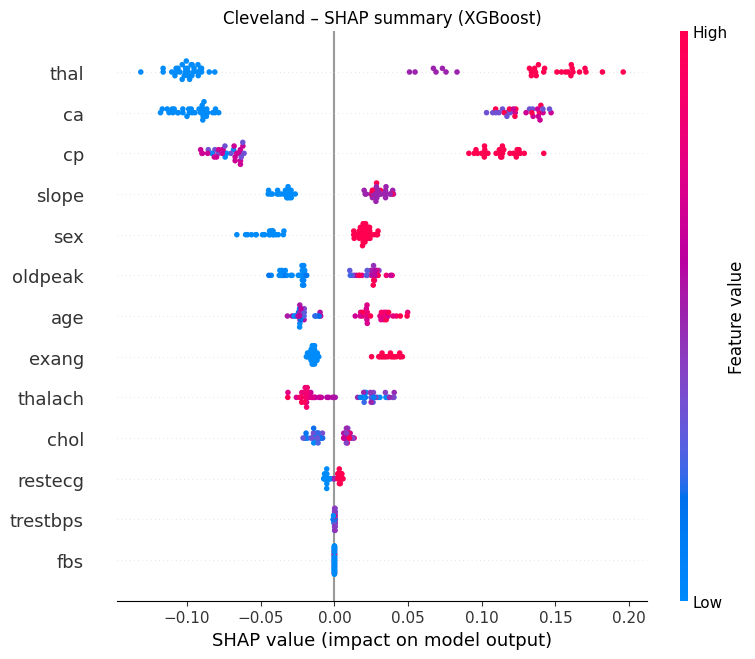

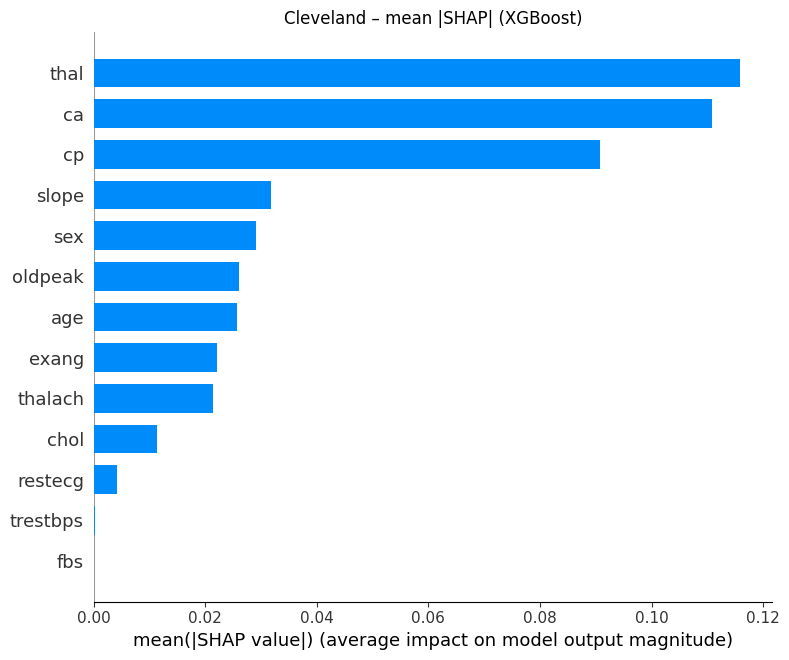

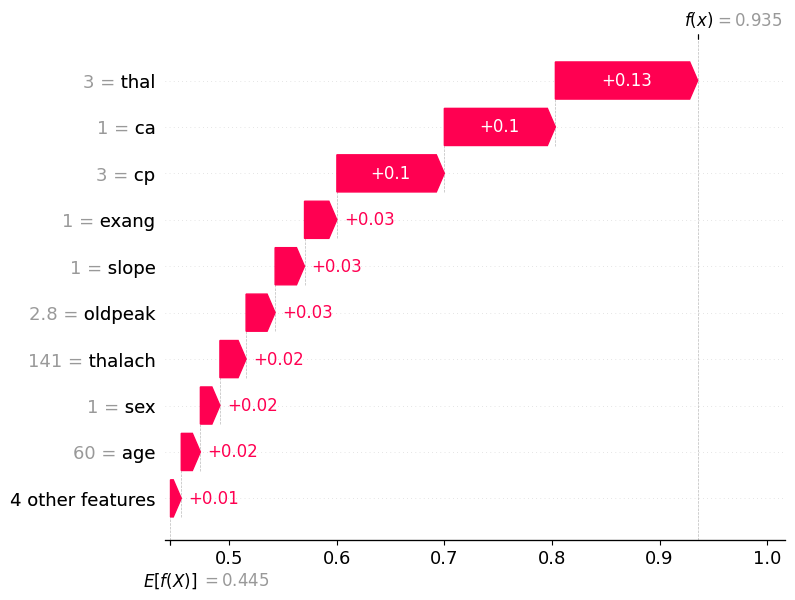


   Plain-language reading for one test patient (predicted probability 0.94, actual label 1):
    • thal = 3 raised the model's score (+0.13 probability contribution).
    • ca = 1 raised the model's score (+0.10 probability contribution).
    • cp = 3 raised the model's score (+0.10 probability contribution).
    • exang = 1 raised the model's score (+0.03 probability contribution).
    • slope = 1 raised the model's score (+0.03 probability contribution).

Framingham: SHAP computed for optimised XGBoost on 848 held-out test patients (units: probability contribution).
   probability-scale SHAP additivity check (mean absolute error): 0.0
   top features: age (0.049), sysBP (0.022), cigsPerDay (0.017), prevalentHyp (0.013), diaBP (0.010)


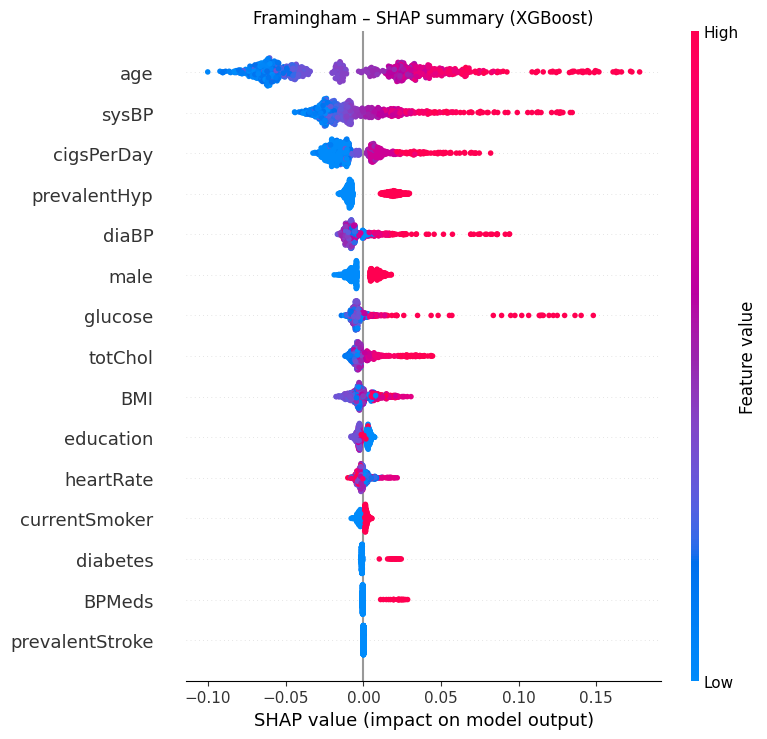

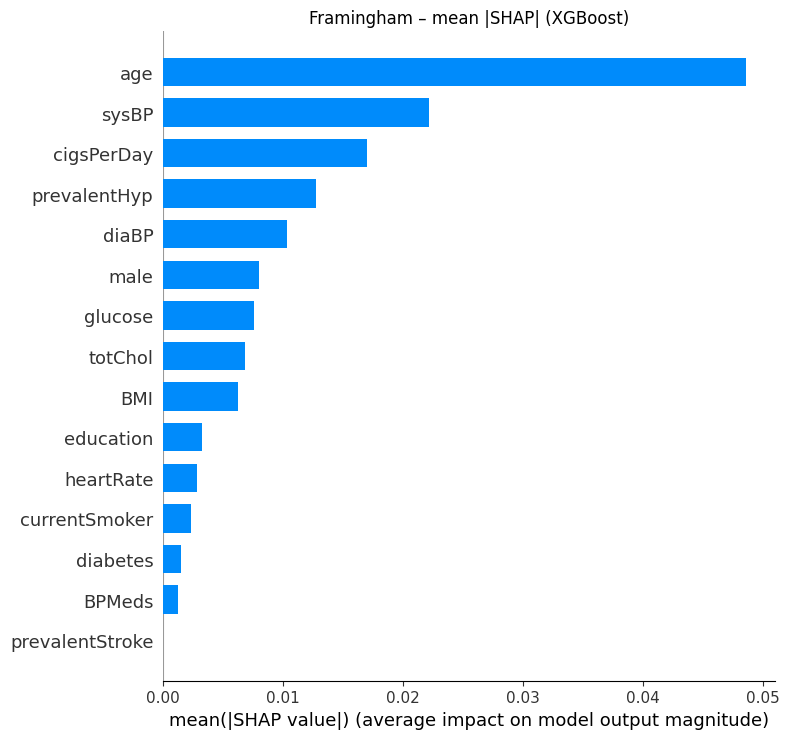

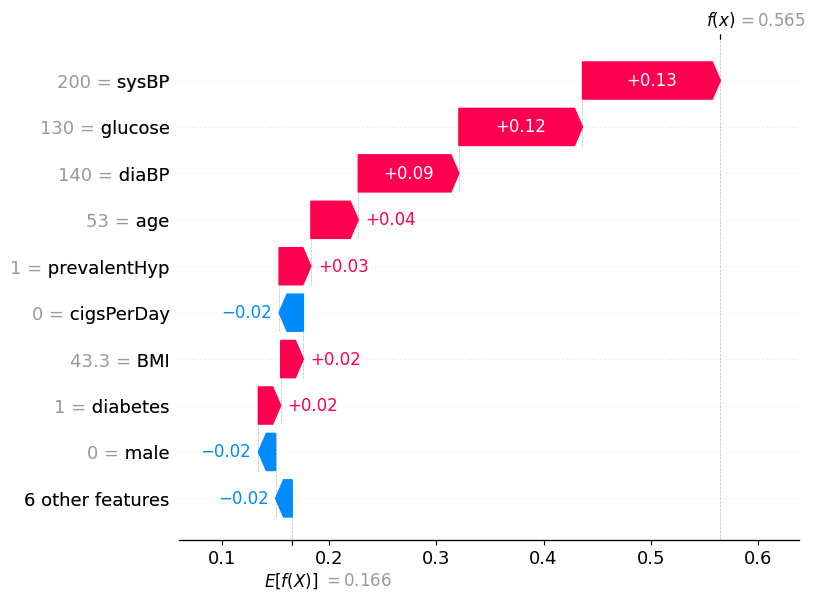


   Plain-language reading for one test patient (predicted probability 0.56, actual label 1):
    • sysBP = 200 raised the model's score (+0.13 probability contribution).
    • glucose = 130 raised the model's score (+0.12 probability contribution).
    • diaBP = 140 raised the model's score (+0.09 probability contribution).
    • age = 53 raised the model's score (+0.04 probability contribution).
    • prevalentHyp = 1 raised the model's score (+0.03 probability contribution).

Reminder: SHAP shows which inputs drove THIS MODEL's output. It does not prove medical causation.


In [12]:
# CELL 11 — SHAP explanations for the best optimised model of each dataset
def compute_shap(model, X_background, X_explain):
    """Return positive-class SHAP values in probability units, expected probability, and explainer."""
    kind = type(model).__name__
    background = shap.sample(X_background, min(100, len(X_background)), random_state=SEED)
    if kind in ("XGBClassifier", "RandomForestClassifier"):
        # Interventional background + probability output makes XGBoost and RF explanations comparable.
        explainer = shap.TreeExplainer(
            model, data=background, feature_perturbation="interventional", model_output="probability"
        )
        sv = explainer.shap_values(X_explain)
        ev = np.atleast_1d(explainer.expected_value)
        if isinstance(sv, list):
            sv, ev = sv[1], ev[1]
        elif np.ndim(sv) == 3:
            sv, ev = sv[:, :, 1], ev[1]
        else:
            ev = ev[0]
        return np.asarray(sv), float(ev), "probability contribution", explainer
    # AdaBoost: model-agnostic KernelExplainer; this can be slower than tree-based explanations.
    f = lambda d: model.predict_proba(pd.DataFrame(d, columns=X_explain.columns))[:, 1]
    explainer = shap.KernelExplainer(f, background)
    sv = explainer.shap_values(X_explain, nsamples=200, silent=True)
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return sv, float(np.atleast_1d(explainer.expected_value)[0]), "probability contribution", explainer

SHAP_OUT = {}
for key, cfg in DATASETS.items():
    name = BEST[key]; pipe = MODELS[(key, "optimized", name)]; sp = SPLITS[key]; model = pipe.named_steps["model"]
    Xtr_t = pipe[:-1].transform(sp["X_train"]); Xte_t = pipe[:-1].transform(sp["X_test"])
    if type(model).__name__ == "AdaBoostClassifier":
        Xte_t = Xte_t.iloc[:100]
    sv, ev, units, _ = compute_shap(model, Xtr_t, Xte_t)
    SHAP_OUT[key] = dict(sv=sv, ev=ev, X=Xte_t, units=units)
    print(f"\n{cfg['label']}: SHAP computed for optimised {name} on {len(Xte_t)} held-out test patients (units: {units}).")
    # SHAP additivity sanity check in the same units as the prediction (positive-class probability).
    check_n = min(20, len(Xte_t))
    model_prob = model.predict_proba(Xte_t.iloc[:check_n])[:, 1]
    shap_prob = ev + sv[:check_n].sum(axis=1)
    print("   probability-scale SHAP additivity check (mean absolute error):",
          round(float(np.mean(np.abs(model_prob - shap_prob))), 6))

    # --- global importance ---
    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=Xte_t.columns).sort_values(ascending=False)
    (ARTIFACT_DIR / key).mkdir(parents=True, exist_ok=True)
    mean_abs.rename("mean_abs_shap").to_csv(ARTIFACT_DIR / key / "shap_mean_abs.csv")
    print("   top features:", ", ".join(f"{f} ({v:.3f})" for f, v in mean_abs.head(5).items()))

    plt.figure(); shap.summary_plot(sv, Xte_t, show=False)
    plt.title(f"{cfg['label']} – SHAP summary ({name})"); plt.tight_layout()
    plt.savefig(RESULTS_DIR / "shap" / f"{key}_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

    plt.figure(); shap.summary_plot(sv, Xte_t, plot_type="bar", show=False)
    plt.title(f"{cfg['label']} – mean |SHAP| ({name})"); plt.tight_layout()
    plt.savefig(RESULTS_DIR / "shap" / f"{key}_shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()

    # --- one individual explanation: the held-out patient with the highest predicted probability ---
    proba = pipe.predict_proba(sp["X_test"].loc[Xte_t.index])[:, 1]
    i = int(np.argmax(proba))
    expl = shap.Explanation(values=sv[i], base_values=ev, data=Xte_t.iloc[i].values, feature_names=list(Xte_t.columns))
    plt.figure(); shap.plots.waterfall(expl, max_display=10, show=False)
    plt.savefig(RESULTS_DIR / "shap" / f"{key}_shap_waterfall_example.png", dpi=150, bbox_inches="tight"); plt.show()

    order = np.argsort(-np.abs(sv[i]))[:5]
    print(f"\n   Plain-language reading for one test patient (predicted probability {proba[i]:.2f}, actual label {int(sp['y_test'].loc[Xte_t.index[i]])}):")
    for j in order:
        f = Xte_t.columns[j]
        print(f"    • {f} = {Xte_t.iloc[i, j]:g} {'raised' if sv[i, j] > 0 else 'lowered'} the model's score ({sv[i, j]:+.2f} {units}).")

    # background sample (used by the app if the best model needs KernelExplainer)
    Xtr_t.sample(min(100, len(Xtr_t)), random_state=SEED).to_csv(ARTIFACT_DIR / key / "shap_background.csv", index=False)

print("\nReminder: SHAP shows which inputs drove THIS MODEL's output. It does not prove medical causation.")


### Cell 11A — SHAP analysis of the final improved Framingham model
Same SHAP method as Cell 11 (`compute_shap`: interventional background from the training data, probability-scale output), now applied to the **final class-weighted model** on the untouched test set. SHAP is used only to *describe* the model; **no feature selection or model change is made from it**. SHAP explains model behaviour and does not establish causality. Because the model was trained with a positive-class weight, its probabilities are shifted upward, so SHAP values are in units of this model's (inflated) score.

In [ ]:
# CELL 11A — SHAP for the FINAL improved Framingham model (test set used for explanation only)
fr_model = FR_W_PIPE.named_steps["model"]
fr_Xtr_t = FR_W_PIPE[:-1].transform(FR_Xtr); fr_Xte_t = FR_W_PIPE[:-1].transform(FR_Xte)
fr_sv, fr_ev, fr_units, _ = compute_shap(fr_model, fr_Xtr_t, fr_Xte_t)
print(f"SHAP computed for the class-weighted XGBoost on {len(fr_Xte_t)} held-out test patients (units: {fr_units}).")
chk_n = min(20, len(fr_Xte_t))
print("probability-scale SHAP additivity check (mean absolute error):",
      round(float(np.mean(np.abs(fr_model.predict_proba(fr_Xte_t.iloc[:chk_n])[:, 1] - (fr_ev + fr_sv[:chk_n].sum(axis=1))))), 6))

FR_SHAP_IMP = pd.Series(np.abs(fr_sv).mean(axis=0), index=fr_Xte_t.columns).sort_values(ascending=False)
(ARTIFACT_DIR / FR).mkdir(parents=True, exist_ok=True)
FR_SHAP_IMP.rename("mean_abs_shap").to_csv(ARTIFACT_DIR / FR / "shap_mean_abs_improved.csv")

top_ = pd.DataFrame({"mean |SHAP|": FR_SHAP_IMP.head(10)})
if FR in SHAP_OUT:     # compare with the original model's ranking from Cell 11 (descriptive only)
    orig_imp = pd.Series(np.abs(SHAP_OUT[FR]["sv"]).mean(axis=0), index=SHAP_OUT[FR]["X"].columns).sort_values(ascending=False)
    top_["rank in original best model (Cell 11)"] = [int(list(orig_imp.index).index(f)) + 1 for f in top_.index]
print("\nTop 10 features of the improved model (mean |SHAP| on the test set):")
display(top_.round(4))
print("Top features:", ", ".join(f"{f} ({v:.3f})" for f, v in FR_SHAP_IMP.head(5).items()))

plt.figure(); shap.summary_plot(fr_sv, fr_Xte_t, show=False)
plt.title("Framingham - SHAP summary (class-weighted XGBoost)"); plt.tight_layout()
plt.savefig(RESULTS_DIR / "shap" / "framingham_improved_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(fr_sv, fr_Xte_t, plot_type="bar", show=False)
plt.title("Framingham - mean |SHAP| (class-weighted XGBoost)"); plt.tight_layout()
plt.savefig(RESULTS_DIR / "shap" / "framingham_improved_shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()
print("\nReminder: SHAP shows which inputs drove THIS MODEL's output. It does not establish causality, and it was not used to select features.")

### Cell 11B — Probability quality (calibration) of the original vs improved model
Brier score and log loss are computed on the **unmodified** model probabilities (lower is better); no recalibration is applied. A constant model that always predicts the *training* prevalence is shown as a reference. Class weighting is expected to push probabilities upward, so worse Brier / log loss than the unweighted model is a normal side-effect and means the weighted scores should be read as risk *scores*, not calibrated probabilities.

In [ ]:
# CELL 11B — Calibration / probability-quality metrics (probabilities are NOT modified)
from sklearn.calibration import calibration_curve
prev_tr = float(np.mean(FR_ytr))
const_ = np.full(len(FR_yte), prev_tr)
cal_rows = []
for lab_, p_ in (("Original XGBoost", FR_PROBA["orig"]), ("Class-weighted XGBoost", FR_PROBA["weighted"]), ("No-skill (constant = training prevalence)", const_)):
    pc_ = np.clip(p_, 1e-7, 1 - 1e-7)
    cal_rows.append(dict(model=lab_, brier_score=brier_score_loss(FR_yte, pc_), log_loss=log_loss(FR_yte, pc_, labels=[0, 1]),
                         mean_predicted_risk=float(np.mean(p_)), observed_positive_rate=float(np.mean(FR_yte))))
FR_CAL = pd.DataFrame(cal_rows)
ref_brier = FR_CAL.loc[2, "brier_score"]
FR_CAL["brier_skill_vs_no_skill"] = 1 - FR_CAL["brier_score"] / ref_brier
display(FR_CAL.round(4))
FR_CAL.to_csv(RESULTS_DIR / "framingham_calibration_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(5.4, 5))
for lab_, p_ in (("Original XGBoost", FR_PROBA["orig"]), ("Class-weighted XGBoost", FR_PROBA["weighted"])):
    frac_, mean_ = calibration_curve(FR_yte, p_, n_bins=8, strategy="quantile")
    ax.plot(mean_, frac_, "o-", label=lab_)
ax.plot([0, 1], [0, 1], "k:", label="perfect calibration"); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed positive fraction")
ax.set_title("Framingham - reliability diagram (test set)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "framingham_calibration.png", dpi=150); plt.show()
print("Probabilities were not rescaled or post-processed to improve these numbers.")

### Cell 11C — How much can the test-set differences be trusted? (bootstrap, evaluation only)
The Framingham test set contains only ~130 positive patients, so every test metric has sampling noise. This cell resamples the **test patients** (1000 times, seed 42) to give 95 % intervals for the final model and for the **paired differences** between the final model and (a) the original model at 0.50 and (b) the original model with a threshold chosen by the same criterion. The models, thresholds and parameters are fixed; nothing is tuned here.

In [ ]:
# CELL 11C — Paired bootstrap over TEST patients (uncertainty of the comparison only; no model or threshold is changed)
BOOTSTRAP_N = 1000
FR_BOOT_METRICS = ["sensitivity", "specificity", "precision", "f1", "balanced_accuracy", "accuracy", "pr_auc", "roc_auc"]

def quick_metrics(y, p, thr):
    pred = p >= thr
    tp = np.sum(pred & (y == 1)); fp = np.sum(pred & (y == 0)); fn = np.sum(~pred & (y == 1)); tn = np.sum(~pred & (y == 0))
    sens = tp / (tp + fn); spec = tn / (tn + fp); prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
    return dict(sensitivity=sens, specificity=spec, precision=prec, f1=f1, balanced_accuracy=(sens + spec) / 2,
                accuracy=(tp + tn) / len(y), pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p))

yb = np.asarray(FR_yte); rng_ = np.random.default_rng(SEED)
systems = {"original@0.50": (FR_PROBA["orig"], 0.5), "original+threshold": (FR_PROBA["orig"], FR_THR_ORIG),
           "final": (FR_PROBA["weighted"], FR_THR_W)}
draws = {k: [] for k in systems}
for _ in range(BOOTSTRAP_N):
    idx_ = rng_.integers(0, len(yb), len(yb))
    if yb[idx_].sum() in (0, len(yb)):
        continue
    for k, (p_, thr_) in systems.items():
        draws[k].append(quick_metrics(yb[idx_], np.asarray(p_)[idx_], thr_))
draws = {k: pd.DataFrame(v) for k, v in draws.items()}

FR_BOOT_CI = pd.DataFrame({m: dict(estimate=float(FR_ROWS["final"][m]), lo=float(draws["final"][m].quantile(0.025)),
                                    hi=float(draws["final"][m].quantile(0.975))) for m in FR_BOOT_METRICS}).T
print(f"FINAL class-weighted model - test metrics with 95 % bootstrap intervals ({len(draws['final'])} resamples):")
display(FR_BOOT_CI.round(3))

FR_BOOT_DIFF = {}
for base_, lab_ in (("original@0.50", "final - original@0.50"), ("original+threshold", "final - original+threshold")):
    rows_ = {}
    for m in FR_BOOT_METRICS:
        d_ = draws["final"][m] - draws[base_][m]
        rows_[m] = dict(difference=float(d_.mean()), lo=float(d_.quantile(0.025)), hi=float(d_.quantile(0.975)))
        FR_BOOT_DIFF[(lab_, m)] = rows_[m]
    print(f"\nPaired difference {lab_} (positive = final model is higher):")
    out_ = pd.DataFrame(rows_).T; out_["CI excludes 0"] = (out_.lo > 0) | (out_.hi < 0)
    display(out_.round(3))
print("A difference is called 'distinguishable from resampling noise' only if its 95 % interval excludes 0. Test labels are used here for uncertainty only.")

### Cell 11D — Final results: before vs after (generated from the actual run)
Every number printed below is read from the variables created by the cells above. The wording changes automatically with the results (e.g. "improved" / "did not improve"), so nothing is typed in by hand. The text is also saved to `results/framingham_before_after_summary.txt`.

In [ ]:
# CELL 11D — Before vs after, honest discussion text generated from the real numbers, and saving of the improved model
FR_LINES = []
def say(s=""):
    print(s); FR_LINES.append(s)

pc = lambda x: f"{100 * x:.1f}%"
pp = lambda x: f"{100 * x:+.1f} percentage points"
b_, a_ = FR_ROWS["original"], FR_ROWS["final"]
t_ = FR_ROWS["thr_only"]; w_ = FR_ROWS["weighted05"]

say("FRAMINGHAM - BEFORE vs AFTER (held-out test set; machine-learning research model, not a clinical tool)")
say("=" * 100)
say(f"BEFORE  (original optimised XGBoost, threshold {b_['threshold']:.2f})")
say(f"  Accuracy {pc(b_['accuracy'])} | Sensitivity {pc(b_['sensitivity'])} | Specificity {pc(b_['specificity'])} | F1 {b_['f1']:.3f} | ROC-AUC {b_['roc_auc']:.3f} | BA {pc(b_['balanced_accuracy'])} | PR-AUC {b_['pr_auc']:.3f}")
say(f"AFTER   (class-weighted XGBoost, scale_pos_weight {FR_WEIGHTED['params']['scale_pos_weight']:.2f}, CV-selected threshold {a_['threshold']:.2f} by '{THRESHOLD_CRITERION}')")
say(f"  Accuracy {pc(a_['accuracy'])} | Sensitivity {pc(a_['sensitivity'])} | Specificity {pc(a_['specificity'])} | F1 {a_['f1']:.3f} | ROC-AUC {a_['roc_auc']:.3f} | BA {pc(a_['balanced_accuracy'])} | PR-AUC {a_['pr_auc']:.3f}")
say()

def verdict(name, before, after, higher_is_better=True, as_pct=True):
    d = after - before; f = pc if as_pct else (lambda x: f"{x:.3f}")
    dtxt = pp(d) if as_pct else f"{d:+.3f}"
    if abs(d) < 5e-4: return f"- {name}: unchanged ({f(before)} -> {f(after)})."
    word = ("improved" if (d > 0) == higher_is_better else "worsened")
    return f"- {name}: {word} ({f(before)} -> {f(after)}, {dtxt})."

say("What changed")
for line in (verdict("Sensitivity", b_["sensitivity"], a_["sensitivity"]),
             verdict("F1-score", b_["f1"], a_["f1"], as_pct=False),
             verdict("Balanced accuracy", b_["balanced_accuracy"], a_["balanced_accuracy"]),
             verdict("PR-AUC", b_["pr_auc"], a_["pr_auc"], as_pct=False),
             verdict("ROC-AUC", b_["roc_auc"], a_["roc_auc"], as_pct=False)):
    say(line)
say(f"- Specificity {'decreased' if a_['specificity'] < b_['specificity'] else 'did not decrease'} ({pc(b_['specificity'])} -> {pc(a_['specificity'])}, {pp(a_['specificity'] - b_['specificity'])}); "
    f"false positives {b_['fp']} -> {a_['fp']}.")
say(f"- Accuracy {'decreased' if a_['accuracy'] < b_['accuracy'] else 'did not decrease'} ({pc(b_['accuracy'])} -> {pc(a_['accuracy'])}, {pp(a_['accuracy'] - b_['accuracy'])}). "
    "This is expected when more positive cases are flagged and is not a failure: accuracy was inflated by the majority class.")
say(f"- True positives {b_['tp']} -> {a_['tp']} of {b_['tp'] + b_['fn']} positive patients (false negatives {b_['fn']} -> {a_['fn']}).")
say()

say("Is the improvement meaningful? (95 % paired bootstrap intervals over test patients, Cell 11C)")
def ci_line(cmp_label, metric, nice):
    d = FR_BOOT_DIFF[(cmp_label, metric)]
    tag = ("distinguishable from resampling noise" if d["lo"] > 0 else
           "WORSE, distinguishable from noise" if d["hi"] < 0 else "NOT distinguishable from resampling noise")
    return f"- {nice}: difference {d['difference']:+.3f} [95 % CI {d['lo']:+.3f}, {d['hi']:+.3f}] -> {tag}."
c0 = "final - original@0.50"; c1 = "final - original+threshold"
say("Final model vs ORIGINAL model at threshold 0.50:")
for m_, n_ in (("sensitivity", "Sensitivity"), ("balanced_accuracy", "Balanced accuracy"), ("f1", "F1"), ("pr_auc", "PR-AUC")):
    say(ci_line(c0, m_, n_))
say("Final model vs ORIGINAL model with a threshold chosen by the same criterion (isolates the effect of class weighting):")
for m_, n_ in (("balanced_accuracy", "Balanced accuracy"), ("f1", "F1"), ("pr_auc", "PR-AUC")):
    say(ci_line(c1, m_, n_))

gain_vs_orig = FR_BOOT_DIFF[(c0, "sensitivity")]["lo"] > 0 and FR_BOOT_DIFF[(c0, "balanced_accuracy")]["lo"] > 0
extra_from_weight = any(FR_BOOT_DIFF[(c1, m)]["lo"] > 0 for m in ("balanced_accuracy", "f1", "pr_auc"))
say()
say("Interpretation")
if gain_vs_orig:
    say("- Compared with the default-threshold original model, minority-class detection improved, and both the sensitivity and balanced-accuracy gains are larger than resampling noise.")
else:
    say("- Compared with the default-threshold original model, the sensitivity / balanced-accuracy gain is NOT clearly larger than resampling noise, so the improvement should not be called established.")
if extra_from_weight:
    say("- Class weighting added a measurable benefit beyond threshold tuning alone on at least one of balanced accuracy, F1 or PR-AUC.")
else:
    say("- Class weighting did NOT add a measurable benefit beyond simply choosing a better threshold for the original model; most of the gain comes from the threshold, not from the weighting.")
if FR_SMOTE is not None:
    say(f"- SMOTE-NC (CV only, training data) {'was preferred by the pre-set rule, but the primary pipeline remains class weighting' if FR_SMOTE['preferred'] else 'was NOT selected; class weighting was simpler and at least as good in CV'}.")
auc_ = a_["roc_auc"]
say(f"- Discrimination is {'weak' if auc_ < 0.70 else 'modest' if auc_ < 0.80 else 'reasonable'} (test ROC-AUC {auc_:.3f}, PR-AUC {a_['pr_auc']:.3f} vs no-skill {float(np.mean(FR_yte)):.3f}); "
    "a threshold or a weight changes which cases are flagged but cannot add information the features do not contain.")
say(f"- Probability quality: Brier {FR_CAL.loc[1, 'brier_score']:.3f} / log loss {FR_CAL.loc[1, 'log_loss']:.3f} for the weighted model vs {FR_CAL.loc[0, 'brier_score']:.3f} / {FR_CAL.loc[0, 'log_loss']:.3f} for the original; "
    "weighted outputs are risk scores, not calibrated probabilities.")
say()
say("CONCLUSION")
say(f"The original model's {pc(b_['accuracy'])} accuracy was misleading because only {pc(b_['sensitivity'])} of positive cases were detected. "
    f"The experimental imbalance-aware model with a cross-validation-selected threshold detects {pc(a_['sensitivity'])} of positive cases "
    f"(balanced accuracy {pc(a_['balanced_accuracy'])}, F1 {a_['f1']:.3f}) at the cost of lower specificity ({pc(a_['specificity'])}) and accuracy ({pc(a_['accuracy'])}). "
    "This is an experimental machine-learning risk-prediction result on one public cohort; it is not clinically validated.")
(RESULTS_DIR / "framingham_before_after_summary.txt").write_text("\n".join(FR_LINES), encoding="utf-8")

# ---- save the improved model and its settings (the existing app artifacts in Cell 12 are left unchanged) ----
imp_dir = ARTIFACT_DIR / FR / "improved"; imp_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(FR_W_PIPE, imp_dir / "class_weighted_xgboost_pipeline.joblib")
(imp_dir / "improved_model_settings.json").write_text(json.dumps(dict(
    seed=SEED, tuning_objective=TUNING_OBJECTIVE, best_params=FR_WEIGHTED["params"], scale_pos_weight_reference_ratio=FR_RATIO,
    threshold_criterion=THRESHOLD_CRITERION, selected_threshold=FR_THR_W,
    cv_objective_mean=FR_WEIGHTED["cv_objective_mean"], cv_objective_std=FR_WEIGHTED["cv_objective_std"],
    test_metrics={k: v for k, v in FR_ROWS["final"].items() if k != "label"}), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("\nSaved: results/framingham_original_vs_improved.csv, framingham_before_after_summary.txt, calibration + threshold tables, "
      "plots/framingham_*.png, artifacts/framingham/improved/")

### Discussion, limitations and conclusion (Framingham improvement experiment)

**Discussion.** The original model achieved relatively high accuracy at the default threshold; however, its very low sensitivity demonstrated poor minority-class detection. Therefore, accuracy alone was not considered sufficient for evaluating the Framingham model. An imbalance-aware training strategy and cross-validation-based threshold optimization were subsequently investigated to improve detection of positive cases.

* Class weighting (`scale_pos_weight`) changes how much the training loss penalises missed positives; the threshold decides how much predicted risk is needed to flag a patient. Both were chosen on **training data only** (Optuna on 5-fold CV, thresholds on out-of-fold predictions), and the test set was used once, for evaluation.
* The threshold-only ablation and the bootstrap intervals above show how much of the change is due to class weighting, how much is due to the threshold, and how much could be sampling noise. The generated text in Cell 11D states the outcome for *this* run, including when the improvement is small.
* SMOTE-NC was examined only by cross-validation inside the training folds and was kept out of the final model unless it clearly beat class weighting.
* SHAP (Cell 11A) describes which inputs the final model relies on; it does not show that those factors cause heart disease, and it was not used to select features.

**Limitations.**
1. One fixed 80/20 split; the test set has only ~130 positive patients, so all test metrics are noisy (see the bootstrap intervals).
2. The same CV folds were used for tuning and for threshold selection, so CV estimates are mildly optimistic; nested CV would be stricter.
3. ROC-AUC / PR-AUC stay modest because the 15 routine risk factors carry limited information; weighting and thresholds cannot create information that is not in the features.
4. Class weighting distorts predicted probabilities (worse Brier score / log loss); the weighted output is a risk score, not a calibrated probability, and no recalibration was applied.
5. The selected threshold depends on the chosen criterion (here F1) and implies a specific trade-off between missed cases and false alarms; a different clinical or research purpose would justify a different trade-off.
6. Median / mode imputation, a single public cohort and no external validation. This is an experimental machine-learning research model, **not** a clinically validated or diagnostic tool.

**Conclusion.** The before-versus-after numbers, the interpretation of whether the improvement is meaningful, and the remaining caveats are generated in Cell 11D from the actual run. The Cleveland results and the paper comparison were not changed.

### Cell 12 — Save everything
Saves each fitted pipeline (preprocessing + model) with joblib, metrics CSVs, plots, metadata, `requirements.txt`, and a ZIP.

In [13]:
# CELL 12 — Save models, preprocessing pipelines, metrics, plots and a downloadable ZIP
import datetime
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    raise TypeError(type(o))

# ---- tables ----
metrics_df = pd.DataFrame(RESULTS)
metrics_df.to_csv(RESULTS_DIR / "model_metrics.csv", index=False)
pd.DataFrame(CV_ROWS).to_csv(RESULTS_DIR / "cv_results.csv", index=False)
BEST_PARAMS_DF.to_csv(RESULTS_DIR / "best_parameters.csv", index=False)
PAPER_COMPARISON.to_csv(RESULTS_DIR / "paper_comparison.csv", index=False)

# ---- per-dataset artifacts ----
for key, cfg in DATASETS.items():
    d = ARTIFACT_DIR / key; (d / "models").mkdir(parents=True, exist_ok=True)
    sp = SPLITS[key]; best = BEST[key]
    # every fitted pipeline (preprocessing + model in ONE object)
    for (k, stage, name), pipe in MODELS.items():
        if k == key:
            joblib.dump(pipe, d / "models" / f"{stage}__{name.replace(' ', '_')}.joblib")
    best_pipe = MODELS[(key, "optimized", best)]
    joblib.dump(best_pipe, d / "best_pipeline.joblib")

    # held-out test data and test probabilities (lets the app draw ROC curves / explain test patients)
    test_df = sp["X_test"].copy(); test_df[cfg["target"]] = sp["y_test"].values
    test_df.to_csv(d / "test_data.csv", index=False)
    preds = pd.DataFrame({"y_true": sp["y_test"].values})
    for (k, stage, name), p in PREDS.items():
        if k == key: preds[f"{stage}__{name}"] = p
    preds.to_csv(d / "test_predictions.csv", index=False)

    # dataset information for the app
    raw = RAW[key]
    info = dict(label=cfg["label"], target=cfg["target"], target_meaning={str(k): v for k, v in cfg["target_meaning"].items()},
                **CLEAN_INFO[key],
                missing={c: dict(count=int(raw[c].isna().sum()), percent=round(float(raw[c].isna().mean() * 100), 2)) for c in raw.columns},
                target_distribution={str(k): int(v) for k, v in raw[cfg["target"]].value_counts().sort_index().items()},
                feature_descriptions={f: dict(group=g, description=desc) for f, (g, desc) in cfg["features"].items()},
                source_file=cfg["file"])
    (d / "dataset_info.json").write_text(json.dumps(info, indent=2, default=jsonable))

    # metadata used by the app
    Xtr = sp["X_train"]
    meta = dict(label=cfg["label"], target=cfg["target"], input_features=cfg["feature_names"],
                numeric=cfg["numeric"], categorical=cfg["categorical"],
                model_features=list(best_pipe[:-1].transform(sp["X_test"].head(2)).columns),
                best_model=best, threshold_default=0.5, threshold_cv=THRESH_CV[key],
                best_params=TUNED[(key, best)]["params"], cv_roc_auc=TUNED[(key, best)]["cv_mean"],
                shap_units=SHAP_OUT[key]["units"], seed=SEED, test_size=TEST_SIZE, cv_folds=CV_FOLDS,
                train_stats={c: dict(min=float(Xtr[c].min()), max=float(Xtr[c].max()), mean=float(Xtr[c].mean()),
                                     median=float(Xtr[c].median()), missing=int(Xtr[c].isna().sum())) for c in Xtr.columns},
                versions=dict(python=platform.python_version(), sklearn=sklearn.__version__, xgboost=xgboost.__version__,
                              shap=shap.__version__, numpy=np.__version__, pandas=pd.__version__),
                created=datetime.datetime.now().isoformat(timespec="seconds"))
    (d / "meta.json").write_text(json.dumps(meta, indent=2, default=jsonable))
    print(f"Saved artifacts/{key}/  (best model: {best})")

# ---- verify that the saved best pipelines reload and reproduce the in-memory predictions ----
for key in DATASETS:
    reloaded = joblib.load(ARTIFACT_DIR / key / "best_pipeline.joblib")
    same = np.allclose(reloaded.predict_proba(SPLITS[key]["X_test"])[:, 1], PREDS[(key, "optimized", BEST[key])])
    print(f"Reload check {key}: predictions identical = {same}")

# ---- ZIP for download ----
zip_path = shutil.make_archive(str(PROJECT_DIR / "heart_results_and_artifacts"), "zip", root_dir=PROJECT_DIR,
                               base_dir="artifacts")
with __import__("zipfile").ZipFile(zip_path, "a") as z:
    for p in RESULTS_DIR.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(PROJECT_DIR))
print("\nZIP created:", zip_path)
print("Saved in:", PROJECT_DIR, "(Google Drive keeps it if you mounted Drive in Cell 3)")
for p in sorted(list(RESULTS_DIR.glob("*.csv")) + list((ARTIFACT_DIR).rglob("*.joblib")))[:40]:
    print("  ", p.relative_to(PROJECT_DIR))

# ---- requirements.txt (needed only if you re-open the app OUTSIDE this Colab session, e.g. on your laptop) ----
REQ = f"""# Heart Disease Prediction project – dependencies
# The saved .joblib files must be loaded with the SAME scikit-learn and xgboost versions that created them
# (they are recorded in artifacts/<dataset>/meta.json). Versions below are the ones this project was tested with.
numpy>=1.26
pandas>=2.1
scikit-learn>=1.4
xgboost>=2.0
shap>=0.45
optuna>=3.5
streamlit>=1.35
matplotlib>=3.8
joblib>=1.3
# tested with: numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, xgboost {xgboost.__version__},
#              shap {shap.__version__}, optuna {optuna.__version__}, matplotlib {__import__('matplotlib').__version__}
"""
(PROJECT_DIR / "requirements.txt").write_text(REQ)
print("\nrequirements.txt written.")


Saved artifacts/cleveland/  (best model: XGBoost)
Saved artifacts/framingham/  (best model: XGBoost)
Reload check cleveland: predictions identical = True
Reload check framingham: predictions identical = True

ZIP created: /content/drive/MyDrive/heart_disease_project/heart_results_and_artifacts.zip
Saved in: /content/drive/MyDrive/heart_disease_project (Google Drive keeps it if you mounted Drive in Cell 3)
   artifacts/cleveland/best_pipeline.joblib
   artifacts/cleveland/models/baseline__AdaBoost.joblib
   artifacts/cleveland/models/baseline__Random_Forest.joblib
   artifacts/cleveland/models/baseline__XGBoost.joblib
   artifacts/cleveland/models/optimized__AdaBoost.joblib
   artifacts/cleveland/models/optimized__Random_Forest.joblib
   artifacts/cleveland/models/optimized__XGBoost.joblib
   artifacts/cleveland/models/paper-params__AdaBoost.joblib
   artifacts/cleveland/models/paper-params__Random_Forest.joblib
   artifacts/cleveland/models/paper-params__XGBoost.joblib
   artifacts/fra

### Cell 13 — Write the Streamlit app (`app.py`)
Creates the full dashboard file. The app only *loads* the saved artifacts; it never retrains.

In [14]:
%%writefile app.py
"""Heart Disease Prediction Using Optimized Ensemble Learning and Explainable AI  (Streamlit dashboard).

The app only LOADS artifacts saved by the notebook (artifacts/<dataset>/..., results/...); it never retrains.
Folder is taken from the HD_PROJECT_DIR environment variable, or the folder that contains this file.
"""
import json
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

ROOT = Path(os.environ.get("HD_PROJECT_DIR", Path(__file__).resolve().parent))
ART, RES = ROOT / "artifacts", ROOT / "results"
PAPER_URL = "https://www.mdpi.com/2078-2489/15/7/394"
PAPER_REF = ("Mienye, I.D.; Jere, N. Optimized Ensemble Learning Approach with Explainable AI for Improved "
             "Heart Disease Prediction. Information 2024, 15(7), 394.")
LABELS = {"cleveland": "Cleveland Heart Disease", "framingham": "Framingham Heart Study"}
PAGES = ["🏠 Home", "📊 Model performance", "🩺 Prediction", "🔍 Explainability", "🗂️ Dataset information"]

st.set_page_config(page_title="Heart Disease Prediction", page_icon="🫀", layout="wide")
st.markdown("""
<style>
.banner{background:linear-gradient(90deg,#0f4c81,#1b7fa8);padding:1.1rem 1.4rem;border-radius:12px;color:white;margin-bottom:1rem}
.banner h1{color:white;font-size:1.6rem;margin:0}.banner p{margin:.3rem 0 0 0;opacity:.9}
</style>""", unsafe_allow_html=True)

AVAILABLE = [k for k in LABELS if (ART / k / "best_pipeline.joblib").exists()]
if not AVAILABLE:
    st.error(f"No saved model artifacts were found in `{ART}`.\n\nRun notebook Cells 1–12 first (and make sure the "
             "project folder is the same one the app is pointed at).")
    st.stop()


# ------------------------------------------------------------------ loading helpers
@st.cache_resource(show_spinner="Loading saved model…")
def load_bundle(ds):
    d = ART / ds
    return dict(pipe=joblib.load(d / "best_pipeline.joblib"),
                meta=json.loads((d / "meta.json").read_text()),
                info=json.loads((d / "dataset_info.json").read_text()),
                test=pd.read_csv(d / "test_data.csv"),
                preds=pd.read_csv(d / "test_predictions.csv"))


@st.cache_data
def load_csv(path):
    return pd.read_csv(path)


@st.cache_resource(show_spinner="Preparing explainer…")
def get_explainer(ds):
    import shap
    b = load_bundle(ds)
    model = b["pipe"].named_steps["model"]
    bg = pd.read_csv(ART / ds / "shap_background.csv")
    if type(model).__name__ in ("XGBClassifier", "RandomForestClassifier"):
        return shap.TreeExplainer(
            model, data=bg, feature_perturbation="interventional", model_output="probability"
        )
    f = lambda d: model.predict_proba(pd.DataFrame(d, columns=bg.columns))[:, 1]
    return shap.KernelExplainer(f, shap.sample(bg, min(100, len(bg)), random_state=42))


def explain_rows(ds, X_raw):
    """Positive-class probability SHAP values for raw-feature rows; returns (values, base, transformed_df)."""
    b = load_bundle(ds)
    model = b["pipe"].named_steps["model"]
    Xt = b["pipe"][:-1].transform(X_raw)
    ex = get_explainer(ds)
    if type(model).__name__ in ("XGBClassifier", "RandomForestClassifier"):
        sv = ex.shap_values(Xt)
        base = np.atleast_1d(ex.expected_value)
        if isinstance(sv, list):
            sv, base = sv[1], base[1]
        elif np.ndim(sv) == 3:
            sv, base = sv[:, :, 1], base[1]
        else:
            base = base[0]
    else:
        sv = ex.shap_values(Xt, nsamples=200, silent=True)
        base = np.atleast_1d(ex.expected_value)[0]
    return np.asarray(sv), float(base), Xt


# ------------------------------------------------------------------ input definitions
YN = {"No (0)": 0, "Yes (1)": 1}
SEX = {"Female (0)": 0, "Male (1)": 1}
SPECS = {
    "cleveland": [
        dict(name="age", label="Age (years)", kind="int", min=18, max=100, step=1),
        dict(name="sex", label="Sex", kind="select", options=SEX),
        dict(name="cp", label="Chest pain type", kind="select",
             options={"0 – typical angina": 0, "1 – atypical angina": 1, "2 – non-anginal pain": 2, "3 – asymptomatic": 3}),
        dict(name="trestbps", label="Resting blood pressure (mm Hg)", kind="int", min=80, max=250, step=1),
        dict(name="chol", label="Serum cholesterol (mg/dL)", kind="int", min=100, max=600, step=1),
        dict(name="fbs", label="Fasting blood sugar > 120 mg/dL", kind="select", options=YN),
        dict(name="restecg", label="Resting ECG result", kind="select",
             options={"0 – normal": 0, "1 – ST-T wave abnormality": 1, "2 – left ventricular hypertrophy": 2}),
        dict(name="thalach", label="Maximum heart rate achieved (bpm)", kind="int", min=60, max=230, step=1),
        dict(name="exang", label="Exercise-induced angina", kind="select", options=YN),
        dict(name="oldpeak", label="ST depression induced by exercise", kind="float", min=0.0, max=7.0, step=0.1),
        dict(name="slope", label="Slope of peak exercise ST segment", kind="select",
             options={"0 – upsloping": 0, "1 – flat": 1, "2 – downsloping": 2}),
        dict(name="ca", label="Major vessels coloured by fluoroscopy", kind="select",
             options={"0": 0, "1": 1, "2": 2, "3": 3}),
        dict(name="thal", label="Thalassemia", kind="select",
             options={"1 – normal": 1, "2 – fixed defect": 2, "3 – reversible defect": 3}),
    ],
    "framingham": [
        dict(name="male", label="Sex", kind="select", options=SEX),
        dict(name="age", label="Age (years)", kind="int", min=20, max=100, step=1),
        dict(name="education", label="Education level (1–4)", kind="select",
             options={"1": 1, "2": 2, "3": 3, "4": 4}, unknown_ok=True),
        dict(name="currentSmoker", label="Current smoker", kind="select", options=YN),
        dict(name="cigsPerDay", label="Cigarettes per day", kind="int", min=0, max=80, step=1, unknown_ok=True),
        dict(name="BPMeds", label="On blood-pressure medication", kind="select", options=YN, unknown_ok=True),
        dict(name="prevalentStroke", label="Previous stroke", kind="select", options=YN),
        dict(name="prevalentHyp", label="Hypertensive", kind="select", options=YN),
        dict(name="diabetes", label="Diabetes", kind="select", options=YN),
        dict(name="totChol", label="Total cholesterol (mg/dL)", kind="int", min=100, max=700, step=1, unknown_ok=True),
        dict(name="sysBP", label="Systolic blood pressure (mm Hg)", kind="float", min=70.0, max=300.0, step=0.5),
        dict(name="diaBP", label="Diastolic blood pressure (mm Hg)", kind="float", min=40.0, max=160.0, step=0.5),
        dict(name="BMI", label="Body mass index (kg/m²)", kind="float", min=12.0, max=60.0, step=0.1, unknown_ok=True),
        dict(name="heartRate", label="Heart rate (bpm)", kind="int", min=40, max=160, step=1, unknown_ok=True),
        dict(name="glucose", label="Glucose (mg/dL)", kind="int", min=40, max=400, step=1, unknown_ok=True),
    ],
}
OUTCOME = {"cleveland": ("Higher likelihood of heart disease (target = 1)", "Lower likelihood of heart disease (target = 0)"),
           "framingham": ("Higher 10-year CHD risk class (TenYearCHD = 1)", "Lower 10-year CHD risk class (TenYearCHD = 0)")}


def show_value(ds, name, value):
    for s in SPECS[ds]:
        if s["name"] == name and s["kind"] == "select":
            for lab, code in s["options"].items():
                if code == value:
                    return lab
    return f"{value:g}" if isinstance(value, (int, float, np.floating)) else str(value)


# ------------------------------------------------------------------ session state / navigation
if "dataset_key" not in st.session_state or st.session_state["dataset_key"] not in AVAILABLE:
    st.session_state["dataset_key"] = AVAILABLE[0]
st.session_state.setdefault("home_ds", st.session_state["dataset_key"])
st.session_state.setdefault("side_ds", st.session_state["dataset_key"])


def _sync(src):
    v = st.session_state[src]
    st.session_state.update(dataset_key=v, home_ds=v, side_ds=v)


st.sidebar.title("🫀 Heart Disease AI")
st.sidebar.selectbox("Dataset", AVAILABLE, format_func=LABELS.get, key="side_ds", on_change=_sync, args=("side_ds",))
page = st.sidebar.radio("Navigate", PAGES)
st.sidebar.warning("Educational / research use only. **Not a medical diagnosis.**")
DS = st.session_state["dataset_key"]
B = load_bundle(DS)
META, INFO = B["meta"], B["info"]

st.markdown("<div class='banner'><h1>Heart Disease Prediction Using Optimized Ensemble Learning and Explainable AI</h1>"
            f"<p>Active dataset: <b>{LABELS[DS]}</b> · best model: <b>{META['best_model']}</b></p></div>", unsafe_allow_html=True)

try:
    import sklearn
    if sklearn.__version__ != META["versions"]["sklearn"]:
        st.caption(f"⚠️ Models were saved with scikit-learn {META['versions']['sklearn']}, but {sklearn.__version__} is installed. "
                   "If you see errors, install the version listed in `meta.json`.")
except Exception:
    pass


# ------------------------------------------------------------------ pages
def page_home():
    st.subheader("About this project")
    st.write("This dashboard reproduces, as closely as an honest evaluation allows, the methodology of Mienye & Jere (2024): "
             "**Random Forest, AdaBoost and XGBoost** classifiers tuned with **Bayesian optimisation** and five-fold "
             "stratified cross-validation, evaluated on a held-out test set, and explained with **SHAP**.")
    st.markdown(f"**Research paper:** {PAPER_REF} [{PAPER_URL}]({PAPER_URL})")
    st.warning("⚠️ **For educational and research purposes only — not medical advice or diagnosis.** Never use this tool "
               "to make decisions about your health; consult a qualified clinician.")
    st.subheader("Choose a dataset")
    st.radio("Dataset", AVAILABLE, format_func=LABELS.get, horizontal=True, key="home_ds", on_change=_sync,
             args=("home_ds",), label_visibility="collapsed")
    t = load_csv(RES / "model_metrics.csv")
    row = t[(t.dataset == DS) & (t.stage == "optimized") & (t.model == META["best_model"]) & (t.split == "test")]
    c = st.columns(4)
    c[0].metric("Records", INFO["rows_clean"])
    c[1].metric("Input features", INFO["n_features"])
    c[2].metric("Best model (by CV AUC)", META["best_model"])
    if len(row):
        c[3].metric("Held-out test ROC-AUC", f"{row.iloc[0].roc_auc:.3f}")
    st.info("Use the sidebar to open the performance, prediction, explainability and dataset pages.")


def page_performance():
    st.subheader(f"Model performance — {LABELS[DS]}")
    m = load_csv(RES / "model_metrics.csv"); m = m[m.dataset == DS]
    cv = load_csv(RES / "cv_results.csv"); cv = cv[cv.dataset == DS]
    st.caption("Do not mix up training, cross-validation and held-out test results. Balanced accuracy, sensitivity and specificity help assess classification behaviour; "
               "Brier score and log loss assess probability quality (lower is better), but do not by themselves guarantee calibration. "
               "The held-out test set is reserved for final evaluation.")
    stage_names = {"baseline": "Baseline (default settings)", "optimized": "Optimized (Bayesian search)",
                   "paper-params": "Paper's reported hyper-parameters", "optimized-cv-threshold": "Best model, CV-selected threshold"}
    tab1, tab2, tab3, tab4, tab5 = st.tabs(["Held-out TEST", "Cross-validation", "Training (for overfitting check)", "Plots", "Calibration"])
    cols = ["stage", "model", "threshold", "accuracy", "balanced_accuracy", "precision",
            "sensitivity", "specificity", "f1", "roc_auc", "brier_score", "log_loss"]
    with tab1:
        t = m[m.split == "test"].copy(); t["stage"] = t["stage"].map(stage_names)
        st.dataframe(t[cols].round(3), hide_index=True)
        piv = m[(m.split == "test") & (m.stage.isin(["baseline", "optimized"]))].pivot(index="model", columns="stage", values="roc_auc")
        st.markdown("**ROC-AUC: baseline vs optimized (test)**"); st.bar_chart(piv)
    with tab2:
        t = cv.copy(); t["stage"] = t["stage"].map(stage_names)
        st.dataframe(t[["stage", "model", "cv_roc_auc_mean", "cv_roc_auc_std"]].round(3), hide_index=True)
        st.caption("Mean ± std of ROC-AUC over five stratified folds of the training set. These are NOT test scores.")
    with tab3:
        t = m[m.split == "train"].copy(); t["stage"] = t["stage"].map(stage_names)
        st.dataframe(t[cols].round(3), hide_index=True)
        st.caption("Training scores close to 1.0 with much lower test scores indicate overfitting.")
    with tab4:
        names = [f"{r.stage} | {r.model}" for r in m[(m.split == "test")].itertuples()]
        pick = st.selectbox("Model", names, index=max(0, names.index(f"optimized | {META['best_model']}")) if f"optimized | {META['best_model']}" in names else 0)
        stg, mdl = [x.strip() for x in pick.split("|")]
        r = m[(m.split == "test") & (m.stage == stg) & (m.model == mdl)].iloc[0]
        c1, c2 = st.columns(2)
        with c1:
            cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
            fig, ax = plt.subplots(figsize=(4, 3.4)); ax.imshow(cm, cmap="Blues")
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=15, color="white" if cm[i, j] > cm.max() * .6 else "black")
            ax.set_xticks([0, 1], ["Pred 0", "Pred 1"]); ax.set_yticks([0, 1], ["True 0", "True 1"])
            ax.set_title(f"Confusion matrix (test, threshold {r.threshold:.2f})", fontsize=9); st.pyplot(fig); plt.close(fig)
        with c2:
            col = f"{stg}__{mdl}" if stg != "optimized-cv-threshold" else f"optimized__{mdl}"
            if col in B["preds"]:
                y, p = B["preds"]["y_true"], B["preds"][col]
                fpr, tpr, _ = roc_curve(y, p)
                fig, ax = plt.subplots(figsize=(4, 3.4)); ax.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y, p):.3f}")
                ax.plot([0, 1], [0, 1], "k:"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
                ax.set_title("ROC curve (held-out test)", fontsize=9); ax.legend(); st.pyplot(fig); plt.close(fig)
    with tab5:
        st.markdown("**Probability calibration diagnostic — best optimized model**")
        st.caption("A reliability curve compares predicted probabilities with the observed positive fraction in each bin. "
                   "The diagonal is ideal. This is a diagnostic only; it does not calibrate the model.")
        best_col = f"optimized__{META['best_model']}"
        if best_col in B["preds"]:
            y_cal = B["preds"]["y_true"].astype(int).to_numpy()
            p_cal = np.clip(B["preds"][best_col].to_numpy(dtype=float), 1e-7, 1 - 1e-7)
            frac_positive, mean_predicted = calibration_curve(y_cal, p_cal, n_bins=5, strategy="quantile")
            fig, ax = plt.subplots(figsize=(5, 4))
            ax.plot(mean_predicted, frac_positive, marker="o", label="Best optimized model")
            ax.plot([0, 1], [0, 1], "k--", label="Ideal calibration")
            ax.set_xlabel("Mean predicted probability")
            ax.set_ylabel("Observed positive fraction")
            ax.set_title("Held-out test reliability curve")
            ax.legend()
            st.pyplot(fig)
            plt.close(fig)
            test_row = m[(m.split == "test") & (m.stage == "optimized") & (m.model == META["best_model"])].iloc[0]
            c1, c2 = st.columns(2)
            c1.metric("Brier score (lower is better)", f"{test_row.brier_score:.4f}")
            c2.metric("Log loss (lower is better)", f"{test_row.log_loss:.4f}")
        else:
            st.info("Test probabilities are missing. Rerun notebook Cells 9–12 to regenerate artifacts.")
    if DS == "framingham":
        st.warning("Framingham is imbalanced (≈15 % positives). Accuracy alone is misleading: a model that predicts everyone "
                   "as negative scores ≈85 % accuracy with 0 % sensitivity. Look at sensitivity and ROC-AUC.")


def validate(ds, vals):
    errs, warns = [], []
    st_ = META["train_stats"]
    if ds == "framingham":
        sbp, dbp = vals["sysBP"], vals["diaBP"]
        if not (np.isnan(sbp) or np.isnan(dbp)) and sbp <= dbp:
            errs.append("Systolic blood pressure must be higher than diastolic blood pressure.")
        cig, smk = vals["cigsPerDay"], vals["currentSmoker"]
        if smk == 0 and not np.isnan(cig) and cig > 0:
            errs.append("'Current smoker' is No, but cigarettes per day is above 0.")
        if smk == 1 and not np.isnan(cig) and cig == 0:
            warns.append("'Current smoker' is Yes but cigarettes per day is 0 — please double-check.")
    for k, v in vals.items():
        if not np.isnan(v) and k in st_ and META["input_features"].count(k):
            lo, hi = st_[k]["min"], st_[k]["max"]
            if v < lo or v > hi:
                warns.append(f"{k} = {v:g} is outside the range seen in training ({lo:g}–{hi:g}); the prediction is an extrapolation.")
    return errs, warns


def page_prediction():
    st.subheader(f"Prediction — {LABELS[DS]}")
    st.warning("Educational/research use only. The displayed probability is a model estimate, not a clinically validated risk.")
    if DS == "cleveland":
        st.caption("Categorical codes must match the uploaded Cleveland dataset's encoding. Verify the codebook before interpreting a category.")
    vals, missing, unknown = {}, [], []
    cols = st.columns(3)
    for i, spec in enumerate(SPECS[DS]):
        with cols[i % 3]:
            unknown_key = f"{DS}_{spec['name']}_unk"
            is_unknown = bool(st.session_state.get(unknown_key, False)) and spec.get("unknown_ok", False)
            key = f"{DS}_{spec['name']}"
            if spec["kind"] == "select":
                selected = st.selectbox(spec["label"], list(spec["options"]), index=None,
                                         placeholder="Select…", key=key, disabled=is_unknown)
                value = None if selected is None else spec["options"][selected]
            elif spec["kind"] == "int":
                value = st.number_input(spec["label"], min_value=int(spec["min"]), max_value=int(spec["max"]),
                                        value=None, step=1, key=key, placeholder=f"{spec['min']}–{spec['max']}",
                                        disabled=is_unknown)
            else:
                value = st.number_input(spec["label"], min_value=float(spec["min"]), max_value=float(spec["max"]),
                                        value=None, step=float(spec["step"]), format="%.1f", key=key,
                                        placeholder=f"{spec['min']}–{spec['max']}", disabled=is_unknown)
            if spec.get("unknown_ok"):
                st.checkbox("Value unknown → impute from training data", key=unknown_key)
            if is_unknown:
                vals[spec["name"]] = np.nan
                unknown.append(spec["name"])
            elif value is None:
                missing.append(spec["label"])
            else:
                vals[spec["name"]] = float(value)

    if st.button("Predict and explain", type="primary"):
        if missing:
            st.error("Please provide a value for: " + ", ".join(missing))
            return
        errors, warnings_ = validate(DS, vals)
        for error in errors:
            st.error(error)
        if errors:
            return
        for warning in warnings_:
            st.warning(warning)
        if unknown:
            st.info("Missing values will be imputed using training-set statistics: " + ", ".join(unknown))

        X = pd.DataFrame([[vals[f] for f in META["input_features"]]], columns=META["input_features"])
        p = float(B["pipe"].predict_proba(X)[0, 1])
        threshold = float(META["threshold_cv"])
        predicted = int(p >= threshold)
        st.session_state.setdefault("last_input", {})[DS] = X

        positive_label, negative_label = OUTCOME[DS]
        st.markdown("### Prediction result")
        c1, c2, c3 = st.columns(3)
        c1.metric("Estimated positive-class probability", f"{p:.1%}")
        c2.metric("CV-selected decision threshold", f"{threshold:.2f}")
        c3.metric("Predicted class", str(predicted))
        st.progress(min(max(p, 0.0), 1.0))
        (st.error if predicted else st.success)(positive_label if predicted else negative_label)
        st.caption(f"At the conventional 0.50 threshold, this same model would classify the record as class {int(p >= 0.5)}.")
        st.info("This probability is not guaranteed to be calibrated and is not an individual's verified medical risk. "
                "A prediction cannot confirm or rule out heart disease.")

        st.markdown("### Why did the model make this prediction?")
        try:
            with st.spinner("Calculating this patient's SHAP explanation…"):
                shap_values, base_value, X_transformed = explain_rows(DS, X)
            contributions = np.asarray(shap_values[0], dtype=float)
            feature_names = list(X_transformed.columns)
            display_values = []
            for feature in feature_names:
                original_value = X.iloc[0][feature]
                display_values.append("Unknown (imputed)" if pd.isna(original_value)
                                      else show_value(DS, feature, float(original_value)))
            explanation = pd.DataFrame({
                "Feature": feature_names,
                "Patient value": display_values,
                "SHAP contribution (probability points)": contributions * 100,
                "Direction": ["Increased model score" if v > 0 else "Decreased model score" if v < 0
                              else "No material change" for v in contributions]
            })
            explanation["Absolute contribution"] = np.abs(contributions)
            explanation = explanation.sort_values("Absolute contribution", ascending=False)
            st.write(f"**Baseline model output:** {base_value:.1%} · **This patient's output:** {p:.1%}")
            st.caption("SHAP contributions are expressed in probability points. Positive values push the model's output higher; "
                       "negative values push it lower. They explain model behaviour, not medical causation.")
            st.dataframe(explanation.drop(columns="Absolute contribution").head(8).round(3), hide_index=True,
                         use_container_width=True)

            import shap
            fig = plt.figure(figsize=(8, 5))
            shap_exp = shap.Explanation(values=contributions, base_values=base_value,
                                        data=X_transformed.iloc[0].values,
                                        feature_names=feature_names)
            shap.plots.waterfall(shap_exp, max_display=10, show=False)
            st.pyplot(fig, clear_figure=True)
            plt.close(fig)

            top = explanation.head(3)
            higher = [row["Feature"] for _, row in top.iterrows()
                      if row["Direction"] == "Increased model score"]
            lower = [row["Feature"] for _, row in top.iterrows()
                     if row["Direction"] == "Decreased model score"]
            summary_parts = []
            if higher:
                summary_parts.append("features pushing the model output higher: " + ", ".join(higher))
            if lower:
                summary_parts.append("features pushing the model output lower: " + ", ".join(lower))
            if summary_parts:
                st.markdown("**Plain-language summary:** The strongest local contributions include " +
                            "; ".join(summary_parts) + ".")
            st.caption("SHAP explanations depend on the model, training data, and background sample. They are not clinical evidence.")
        except Exception as exc:
            st.warning("The prediction completed, but its SHAP explanation could not be generated. "
                       "Check the SHAP version and saved artifacts, then rerun the SHAP cell. "
                       f"Technical detail: {type(exc).__name__}: {exc}")


def page_explain():
    st.subheader(f"Explainability (SHAP) — {LABELS[DS]}")
    st.caption(f"SHAP explains the {META['best_model']} model in positive-class probability units. "
               "Contributions describe what the model relied on; they do not prove that a feature causes heart disease.")
    t1, t2 = st.tabs(["Global importance", "Individual explanation"])
    with t1:
        c1, c2 = st.columns(2)
        for col, f, cap in ((c1, f"{DS}_shap_summary.png", "SHAP summary (beeswarm)"), (c2, f"{DS}_shap_bar.png", "Mean |SHAP|")):
            p = RES / "shap" / f
            if p.exists():
                col.image(str(p), caption=cap)
        ma = ART / DS / "shap_mean_abs.csv"
        if ma.exists():
            df = pd.read_csv(ma); df.columns = ["feature", "mean_abs_shap"]
            st.dataframe(df.round(4), hide_index=True)
            top = ", ".join(df.feature.head(3))
            st.write(f"Across the explained test patients, the model's output depended most on **{top}**.")
    with t2:
        src = st.radio("Which patient?", ["A held-out test patient", "The last patient entered on the Prediction page"], horizontal=True)
        X = None
        if src.startswith("A held"):
            idx = st.number_input("Test patient number", min_value=0, max_value=len(B["test"]) - 1, value=0, step=1)
            X = B["test"].iloc[[int(idx)]][META["input_features"]]
            st.caption(f"Actual label of this patient: {int(B['test'].iloc[int(idx)][META['target']])}")
        else:
            X = st.session_state.get("last_input", {}).get(DS)
            if X is None:
                st.info("Enter and submit a patient on the Prediction page first.")
        if X is not None:
            sv, base, Xt = explain_rows(DS, X)
            p = float(B["pipe"].predict_proba(X)[0, 1])
            st.metric("Model-estimated probability", f"{p:.1%}")
            import shap
            expl = shap.Explanation(values=sv[0], base_values=base, data=Xt.iloc[0].values, feature_names=list(Xt.columns))
            fig = plt.figure(); shap.plots.waterfall(expl, max_display=10, show=False); st.pyplot(plt.gcf()); plt.close("all")
            st.markdown("**In plain language** (top factors for this patient):")
            for j in np.argsort(-np.abs(sv[0]))[:5]:
                f = Xt.columns[j]; val = show_value(DS, f, float(X.iloc[0][f])) if not np.isnan(X.iloc[0][f]) else "unknown (imputed)"
                st.write(f"- **{f}** = {val} → {'pushed the model\'s score **up**' if sv[0][j] > 0 else 'pushed the model\'s score **down**'} "
                         f"({sv[0][j]:+.3f} {META['shap_units']}).")
            st.caption("Explanations are about the model's behaviour on this record, not about medical causation.")


def page_info():
    st.subheader(f"Dataset information — {LABELS[DS]}")
    c = st.columns(5)
    c[0].metric("Records", INFO["rows_clean"]); c[1].metric("Input features", INFO["n_features"])
    c[2].metric("Training set", INFO["train_size"]); c[3].metric("Test set", INFO["test_size"])
    c[4].metric("Duplicates removed", INFO["duplicates_removed"])
    st.write(f"Source file: `{INFO['source_file']}` · target column: `{INFO['target']}` · split: stratified, seed {META['seed']}, "
             f"test size {META['test_size']:.0%}.")
    td = INFO["target_distribution"]; tot = sum(td.values())
    st.markdown("**Target distribution**")
    st.dataframe(pd.DataFrame({"class": list(td), "meaning": [INFO["target_meaning"][k] for k in td], "count": list(td.values()),
                               "percent": [round(v / tot * 100, 1) for v in td.values()]}), hide_index=True)
    st.write(f"Positives in training: {INFO['train_positive']} / {INFO['train_size']} · in test: {INFO['test_positive']} / {INFO['test_size']}")
    st.markdown("**Missing values (raw file)**")
    ms = pd.DataFrame(INFO["missing"]).T.reset_index().rename(columns={"index": "column"})
    st.dataframe(ms, hide_index=True)
    st.markdown("**Feature descriptions**")
    st.dataframe(pd.DataFrame(INFO["feature_descriptions"]).T.reset_index().rename(columns={"index": "feature"}), hide_index=True)
    st.markdown("**Training-set feature statistics**")
    st.dataframe(pd.DataFrame(META["train_stats"]).T.round(2))


{PAGES[0]: page_home, PAGES[1]: page_performance, PAGES[2]: page_prediction,
 PAGES[3]: page_explain, PAGES[4]: page_info}[page]()


Overwriting app.py


### Cell 14 — Launch Streamlit + public tunnel
Starts the app and creates a public link with a Cloudflare quick tunnel (localtunnel as fallback).

In [15]:
# CELL 14 — Launch Streamlit and expose it through a public tunnel
# Primary method : Cloudflare "quick tunnel" (cloudflared) – free, no account, but the URL changes every run
#                  and there is no uptime guarantee. Requirements: internet access from Colab and an x86-64/arm64 Linux VM.
# Fallback method: localtunnel (needs Node/npm, which Colab has). Visitors must enter a tunnel password (your Colab VM's public IP).
import subprocess, time, re, urllib.request, urllib.error, platform, os, sys
from pathlib import Path

PORT = 8501
APP_PATH = PROJECT_DIR / "app.py"
if not APP_PATH.exists():
    raise FileNotFoundError(f"{APP_PATH} not found. Run Cell 13 first.")
ready = [k for k in ("cleveland", "framingham") if (ARTIFACT_DIR / k / "best_pipeline.joblib").exists()]
if not ready:
    raise FileNotFoundError(f"No saved models in {ARTIFACT_DIR}. Run Cells 1-12, or restore the 'artifacts' folder from Drive / the ZIP.")
print("Saved models found for:", ready)

# 1) stop anything left over from an earlier run  ('[s]' stops pkill from matching its own command line)
subprocess.run("pkill -f '[s]treamlit run'; pkill -f '[c]loudflared tunnel'; pkill -f '[l]t --port'; true", shell=True)
time.sleep(1)

# 2) start Streamlit in the background
env = dict(os.environ, HD_PROJECT_DIR=str(PROJECT_DIR))
st_log = open("/tmp/streamlit.log", "w")
st_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", str(APP_PATH), "--server.port", str(PORT), "--server.headless", "true",
     "--server.enableCORS", "false", "--server.enableXsrfProtection", "false", "--browser.gatherUsageStats", "false"],
    stdout=st_log, stderr=subprocess.STDOUT, env=env, cwd=str(PROJECT_DIR))

ok = False
for _ in range(60):
    try:
        if urllib.request.urlopen(f"http://localhost:{PORT}/_stcore/health", timeout=2).read().decode().strip() == "ok":
            ok = True; break
    except Exception:
        pass
    if st_proc.poll() is not None:
        break
    time.sleep(1)
if not ok:
    print(open("/tmp/streamlit.log").read()[-3000:])
    raise RuntimeError("Streamlit did not start. The log above shows why (most often: a missing package or artifacts folder).")
print(f"Streamlit is running locally on port {PORT}.")

# 3) public tunnel helpers
def read_url(logfile, pattern, timeout=60):
    t0 = time.time()
    while time.time() - t0 < timeout:
        m = re.search(pattern, Path(logfile).read_text(errors="ignore"))
        if m:
            return m.group(0)
        time.sleep(1)
    return None

def verify(url, tries=12):
    for _ in range(tries):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0", "bypass-tunnel-reminder": "1"})
            return urllib.request.urlopen(req, timeout=10).status
        except urllib.error.HTTPError as e:
            if e.code in (401, 403): return e.code           # reachable (localtunnel password page)
        except Exception:
            pass
        time.sleep(5)
    return None

APP_URL = None
# 3a) Cloudflare quick tunnel
try:
    arch = platform.machine().lower()
    asset = "cloudflared-linux-arm64" if arch in ("aarch64", "arm64") else "cloudflared-linux-amd64"
    cf = Path("/tmp/cloudflared")
    if not cf.exists():
        print("Downloading cloudflared ...")
        urllib.request.urlretrieve(f"https://github.com/cloudflare/cloudflared/releases/latest/download/{asset}", cf)
        cf.chmod(0o755)
    print(subprocess.run([str(cf), "--version"], capture_output=True, text=True, timeout=30).stdout.strip())
    cf_log = open("/tmp/cloudflared.log", "w")
    subprocess.Popen([str(cf), "tunnel", "--url", f"http://localhost:{PORT}", "--no-autoupdate"], stdout=cf_log, stderr=subprocess.STDOUT)
    # (?!api\.) below skips Cloudflare's own API host, which also appears in the log
    APP_URL = read_url("/tmp/cloudflared.log", r"https://(?!api\.)[-a-z0-9]+\.trycloudflare\.com", timeout=60)
    if APP_URL:
        print("Checking that the public URL answers (can take up to a minute) ...")
        status = verify(APP_URL)
        print("Reachability check:", "OK (HTTP %s)" % status if status else "no answer yet – try opening the link anyway")
    else:
        print("Cloudflare tunnel did not report a URL. Last log lines:\n", Path("/tmp/cloudflared.log").read_text()[-1200:])
except Exception as e:
    print("Cloudflare tunnel failed:", repr(e))

# 3b) fallback: localtunnel
if not APP_URL:
    print("\nTrying the localtunnel fallback ...")
    try:
        subprocess.run("npm install -g localtunnel", shell=True, check=True, capture_output=True, timeout=180)
        lt_log = open("/tmp/lt.log", "w")
        subprocess.Popen(["lt", "--port", str(PORT)], stdout=lt_log, stderr=subprocess.STDOUT)
        APP_URL = read_url("/tmp/lt.log", r"https://[-a-z0-9]+\.loca\.lt", timeout=60)
        if APP_URL:
            ip = urllib.request.urlopen("https://ipv4.icanhazip.com", timeout=10).read().decode().strip()
            print(f"localtunnel password (enter it on the page that opens): {ip}")
    except Exception as e:
        print("localtunnel failed:", repr(e))

print("\n" + "=" * 70)
if APP_URL:
    print("OPEN YOUR APP HERE  ->", APP_URL)
    print("(Keep this Colab session running. The link stops working when the runtime disconnects.)")
else:
    print("No public URL could be created. See Cell 15 -> 'Troubleshooting'. The app itself IS running on port", PORT)
print("=" * 70)


Saved models found for: ['cleveland', 'framingham']
Streamlit is running locally on port 8501.
cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)
Checking that the public URL answers (can take up to a minute) ...
Reachability check: OK (HTTP 200)

OPEN YOUR APP HERE  -> https://payday-mothers-spatial-activated.trycloudflare.com
(Keep this Colab session running. The link stops working when the runtime disconnects.)


### Cell 15 — Using the app, downloading results, troubleshooting
**Open the app:** click the `https://….trycloudflare.com` link printed by Cell 14 (wait ~10 s on first load).

**Test predictions:** sidebar → *Prediction*; fill **every** field (nothing is pre-filled on purpose), press *Predict*. Try an inconsistent entry (systolic < diastolic) to see validation. Then open *Explainability → Individual explanation*.

**Download results:** run the cell below, or open Google Drive → `MyDrive/heart_disease_project/` (`results/`, `artifacts/`, `app.py`, `requirements.txt`, `heart_results_and_artifacts.zip`).

**Re-open the app later (no retraining):** new runtime → run Cell 1, Cell 2, then in Cell 3 keep `USE_GOOGLE_DRIVE = True` and set `RELAUNCH_ONLY = True` → run Cell 14. (If `app.py` is missing, re-run Cell 13 — it only needs the saved artifacts.)

**Troubleshooting**
| Symptom | Fix |
|---|---|
| *Dataset file(s) not found* | Upload the CSVs when Cell 3 asks, or copy them into `heart_disease_project/data`; names must match exactly. |
| *Missing expected column(s)* | The CSV is a different version; the message lists the columns found vs. expected. |
| Cell 14: no URL | Re-run Cell 14 (tunnels occasionally fail). Check `/tmp/cloudflared.log`. Make sure the Colab runtime has internet access. The localtunnel fallback shows a password = the VM's public IP. |
| App shows "No saved model artifacts" | Run Cells 1–12 first, or restore `artifacts/` and `results/` from the ZIP into the project folder. |
| Pickle / version errors on load | Use the library versions listed in `artifacts/<dataset>/meta.json` / `requirements.txt`. |
| Link stopped working | The Colab runtime disconnected; re-run Cell 14 (a new URL is generated). |

**Limitations / differences from the paper**
1. Exact numbers cannot be reproduced: the paper omits the split, seeds, preprocessing, BO library and missing-value handling.
2. Optuna TPE replaces the paper's unspecified Bayesian optimiser; extra search parameters (marked `(+)` in Cell 8) were added at your request.
3. The best model is chosen by training-CV AUC, not by test AUC as in the paper's Algorithm 1 (avoids test-set selection).
4. Cleveland's test set has only 61 patients, so one patient changes accuracy by ~1.6 points: expect wide uncertainty.
5. Framingham is imbalanced (~15 % positive); high accuracy can hide near-zero sensitivity. An extra row with a CV-selected decision threshold is reported.
6. Several paper table rows are internally inconsistent (Cell 10); the paper's Framingham specificity differs between abstract (0.921) and Table 6 (0.931) — Table 6 is used.
7. Probabilities are uncalibrated model outputs, not clinical risk; SHAP shows model behaviour, not causation.
8. No external validation; models are for education and research only.
9. Framingham improvement experiment (Cells 9A–9G, 11A–11D): the class-weighted model and its CV-selected threshold are an experimental research model. The Streamlit app (Cells 13–14) still uses the original saved best pipeline; the improved pipeline and its settings are saved separately in `artifacts/framingham/improved/`.


In [16]:
# CELL 15 — Download your files (works in Colab; elsewhere it just prints the paths)
to_download = [PROJECT_DIR / "heart_results_and_artifacts.zip", PROJECT_DIR / "app.py", PROJECT_DIR / "requirements.txt",
               RESULTS_DIR / "model_metrics.csv", RESULTS_DIR / "best_parameters.csv", RESULTS_DIR / "paper_comparison.csv"]
for p in to_download:
    print(("found   " if p.exists() else "MISSING ") + str(p))
if IN_COLAB:
    from google.colab import files
    for p in to_download:
        if p.exists():
            files.download(str(p))


found   /content/drive/MyDrive/heart_disease_project/heart_results_and_artifacts.zip
found   /content/drive/MyDrive/heart_disease_project/app.py
found   /content/drive/MyDrive/heart_disease_project/requirements.txt
found   /content/drive/MyDrive/heart_disease_project/results/model_metrics.csv
found   /content/drive/MyDrive/heart_disease_project/results/best_parameters.csv
found   /content/drive/MyDrive/heart_disease_project/results/paper_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>